# WildSpeech — full experiment in one notebook

Runs every stage **P00 → P15** and shows each stage's summary, **all of its plots inline**, and its tables, in order.

* Run top to bottom (`Run All`). Each section runs its own stage; upstream stages are resolved automatically.
* Completed stages with an unchanged fingerprint are **cached** (load instantly); interrupted stages resume from their checkpoints.
* A failing stage prints its traceback and the notebook carries on; stages that depend on it show as `blocked`.
* Re-run one stage from scratch: put its id in `FORCE`, e.g. `FORCE = ["P07"]`.
* Optional/expensive stages (P03 phonetic, P04 embeddings, P14 submission) only run when their switch is on.

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "configs" / "default.yaml").exists(), "open this notebook from inside the WildSpeech_GPU repository"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONUTF8", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
%matplotlib inline
print("repository:", ROOT)

repository: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU


## 0 · Configuration

In [2]:
PROFILE = "FULL"           # SMOKE | FAST | FULL | RESEARCH
FORCE = []                 # stage ids to recompute even if cached, e.g. ["P10"]
OVERRIDES = {
    # "gpu": {"batch_size": 32},
    # "validation": {"n_repeats": 2},
}
RUN_PHONETIC   = False     # P03: local ASR / alignment (needs downloaded, licence-verified models)
RUN_EMBEDDINGS = False     # P04: foundation-model embeddings (same)
RUN_SUBMISSION = False     # P14: test inference with the frozen champion (only after reviewing P13)

TABLE_ROWS = 12            # rows shown per table
SHOW_ALL_TABLES = True     # False = only the key tables listed in each section

In [3]:
from wildspeech.notebook_helpers import setup

if RUN_PHONETIC:
    OVERRIDES.setdefault("phonetic", {})["enabled"] = True
if RUN_EMBEDDINGS:
    OVERRIDES.setdefault("embeddings", {})["enabled"] = True

ctx, pipe = setup(PROFILE, OVERRIDES, root=ROOT)
print("profile:", PROFILE, "| device:", ctx.device, "| data:", ctx.paths.data_dir)
display(Markdown("**Plan** (dry run — nothing executed yet)"))
display(pipe.run(None, force=FORCE, dry_run=True))

14:19:22 | INFO    | context: profile=FULL device=cuda root=C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU data=C:\Users\myben\Downloads\WildSpeech_P01\data


profile: FULL | device: cuda | data: C:\Users\myben\Downloads\WildSpeech_P01\data


**Plan** (dry run — nothing executed yet)

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P02,cached,2026-11-20T14:12:27
3,P05,cached,2026-11-20T14:17:35
4,P06,cached,2026-11-20T14:19:09
5,P07,would_run,residual discovery
6,P08,would_run,robustness
7,P09,would_run,literacy indices
8,P10,would_run,model benchmark + family ablations
9,P11,would_run,"fusion, residual learning, neural MIL / transf..."


In [4]:
RUN_LOG = []


def _summary_frame(summary: dict) -> pd.DataFrame:
    rows = []
    for k, v in (summary or {}).items():
        if isinstance(v, (dict, list)):
            v = json.dumps(v, default=str)[:300]
        rows.append({"key": k, "value": v})
    return pd.DataFrame(rows)


def show_results(sid: str, key_tables=(), rows: int = TABLE_ROWS, all_tables: bool = SHOW_ALL_TABLES):
    """Status + summary, every figure inline (with its data table), then key tables, then the rest."""
    d = ctx.stage_dir(sid)
    st = pipe.status(sid)
    status = st.get("status", "never_run")
    display(Markdown(f"### {sid} · `{status}`" + (f" · {st.get('seconds', 0):.1f}s" if st.get("seconds") else "")
                     + (f" — {st.get('note')}" if st.get("note") else "")))
    if status == "failed":
        print(st.get("traceback", ""))
        return
    if st.get("summary"):
        display(_summary_frame(st["summary"]))
    figs = sorted((d / "figures").glob("*.png")) if (d / "figures").exists() else []
    if figs:
        display(Markdown(f"#### Figures ({len(figs)})"))
    for p in figs:
        display(Markdown(f"**{p.stem}**"))
        display(Image(filename=str(p)))
    all_names = sorted(p.stem for p in (d / "tables").glob("*.csv") if not p.stem.startswith("fig_")) \
        if (d / "tables").exists() else []
    names = [n for n in key_tables if n in all_names] + ([n for n in all_names if n not in key_tables] if all_tables else [])
    if names:
        display(Markdown(f"#### Tables ({len(names)} of {len(all_names)})"))
    for n in names:
        df = ctx.read_stage_table(sid, n)
        if df is None:
            continue
        display(Markdown(f"**{n}** — {len(df)} rows × {df.shape[1]} cols" + (" · *key*" if n in key_tables else "")))
        display(df.head(rows))
    for j in sorted(d.glob("*.json")):
        if j.name.startswith("_"):
            continue
        display(Markdown(f"**{j.name}**"))
        txt = j.read_text(encoding="utf-8")
        print(txt[:2000] + (" …" if len(txt) > 2000 else ""))


def stage(sid: str, key_tables=(), force: bool | None = None):
    """Run one stage (deps resolved, cached if unchanged) and show everything it produced."""
    t0 = time.perf_counter()
    f = [sid] if (force or sid in FORCE) else []
    res = pipe.run([sid], force=f)
    RUN_LOG.append(res.assign(wall_s=round(time.perf_counter() - t0, 1)))
    display(res)
    show_results(sid, key_tables)

---
## P00 · Infrastructure
Hardware, GPU benchmark, CPU↔GPU numerical parity, data integrity, TAR manifests.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49


### P00 · `completed` · 24.0s

,key,value
0,integrity_fail,0
1,integrity_warn,0
2,cuda,True
3,gpu,NVIDIA GeForce RTX 3070 Laptop GPU
4,recommended_batch,32
5,parity_pass_frac,1
6,cache_rows,0


#### Figures (1)

**gpu_throughput_by_batch**

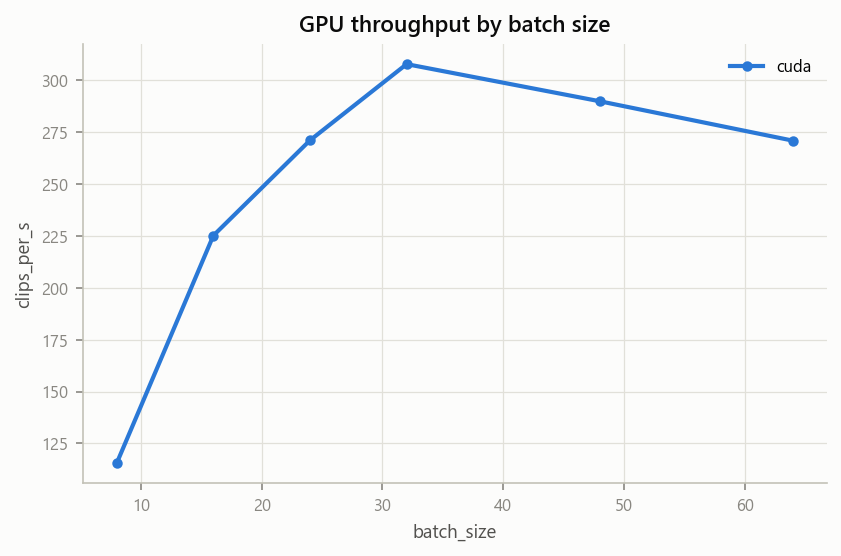

#### Tables (9 of 9)

EmptyDataError: No columns to parse from file

In [9]:
stage('P00')

---
## P01 · Tabular EDA + baselines
Target distribution, screening thetas, items/IRT, adaptive behaviour, and the tabular baselines every later model must beat.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08


### P01 · `completed` · 19.1s

,key,value
0,n_train,541
1,best_baseline,B03_RIDGE_SCR_BEH_ITEM
2,best_r2,0.212


#### Figures (8)

**item_difficulty_vs_syllables**

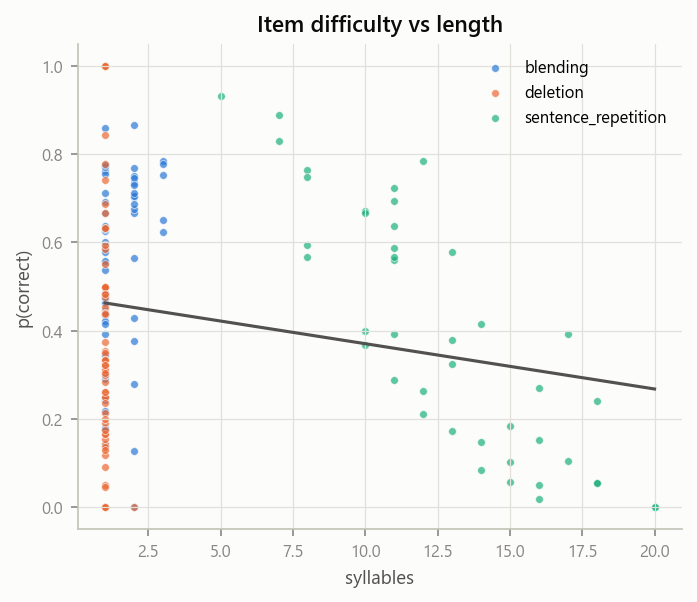

**item_exposure**

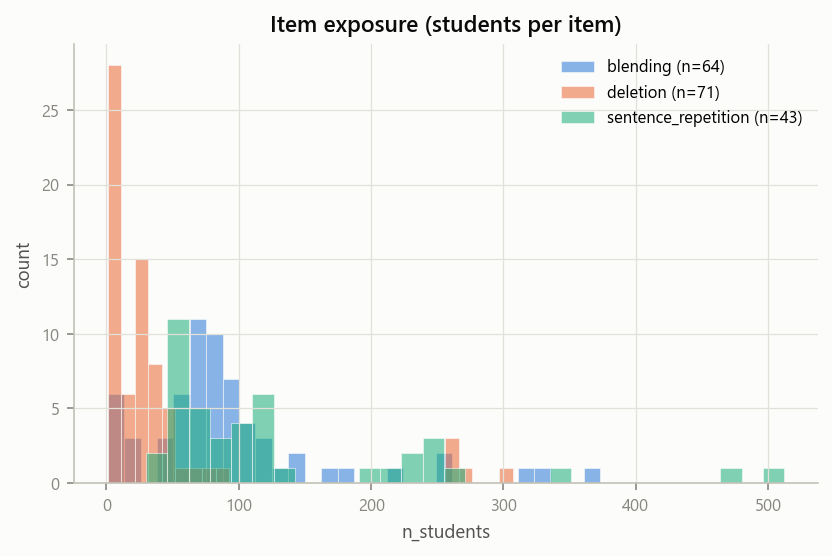

**scatter_blending_theta**

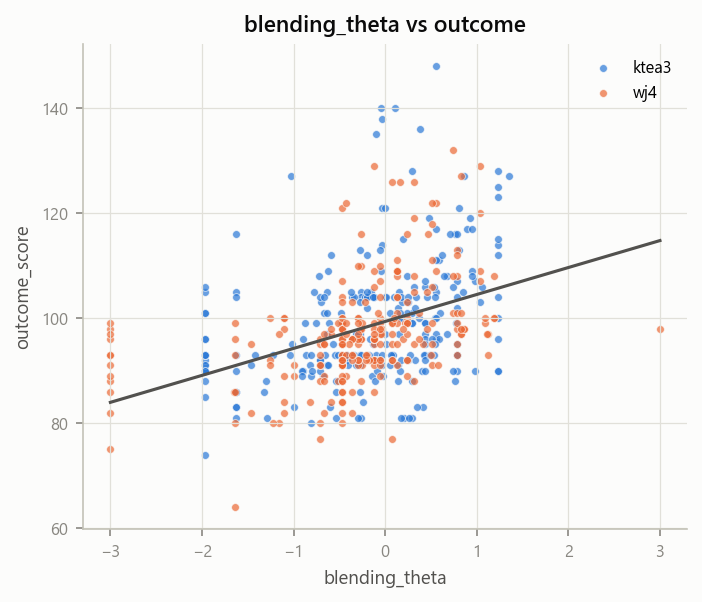

**scatter_deletion_theta**

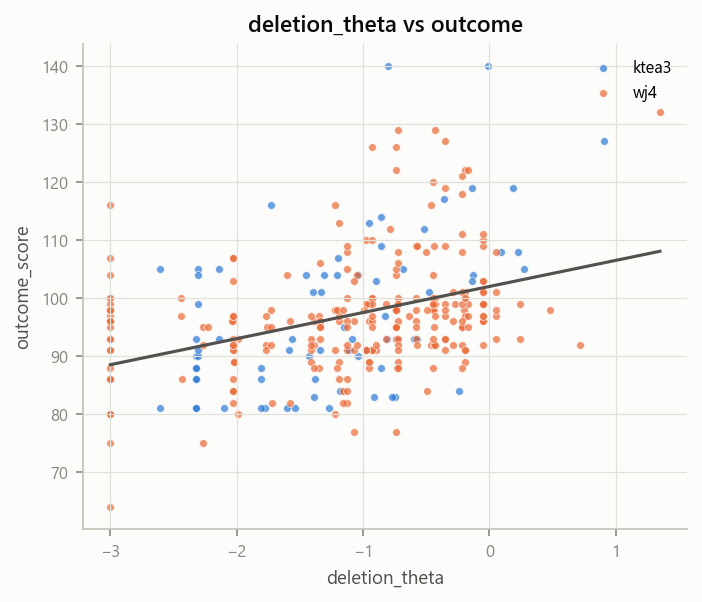

**scatter_sentence_repetition_theta**

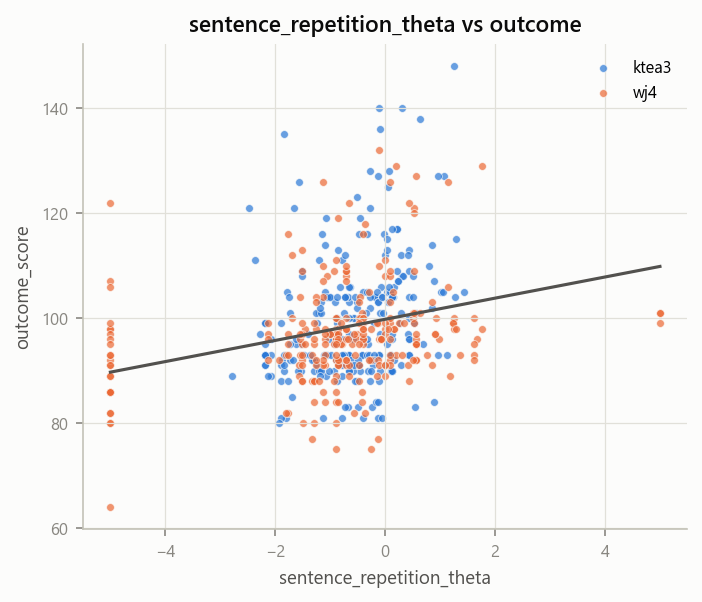

**tabular_baselines_r2**

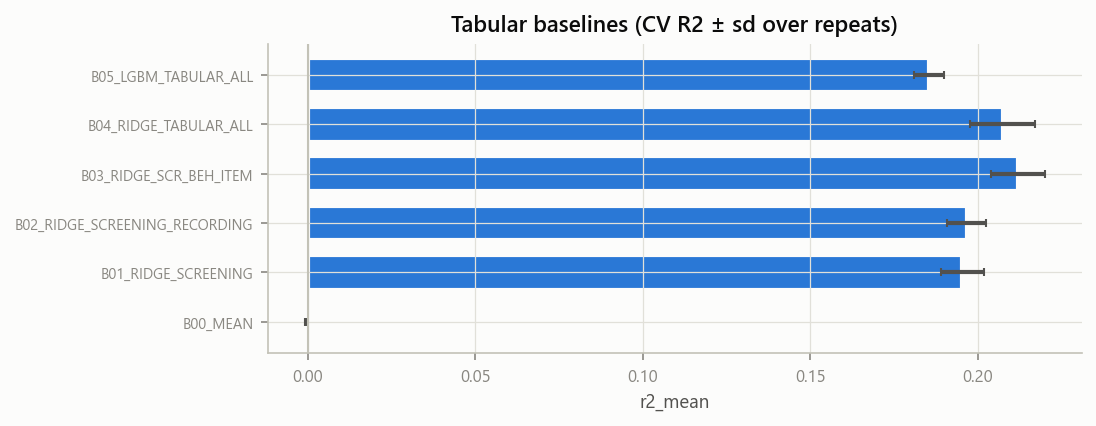

**target_by_instrument**

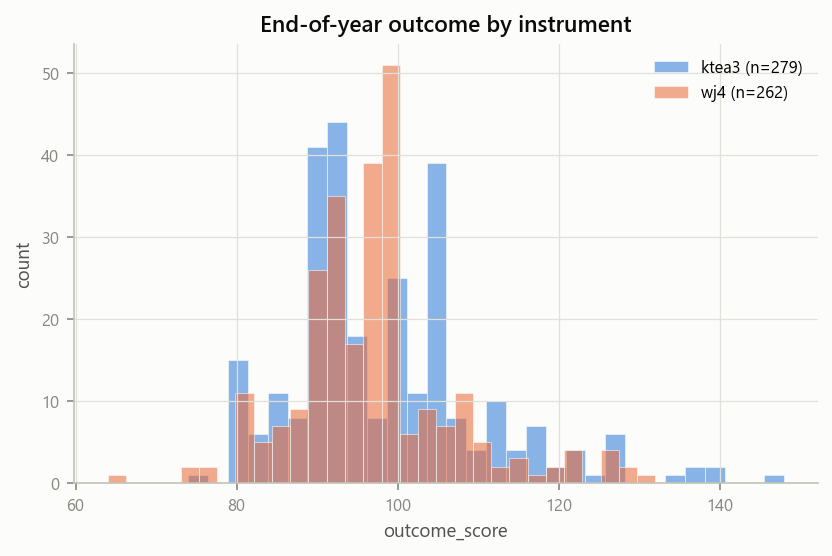

**target_by_school**

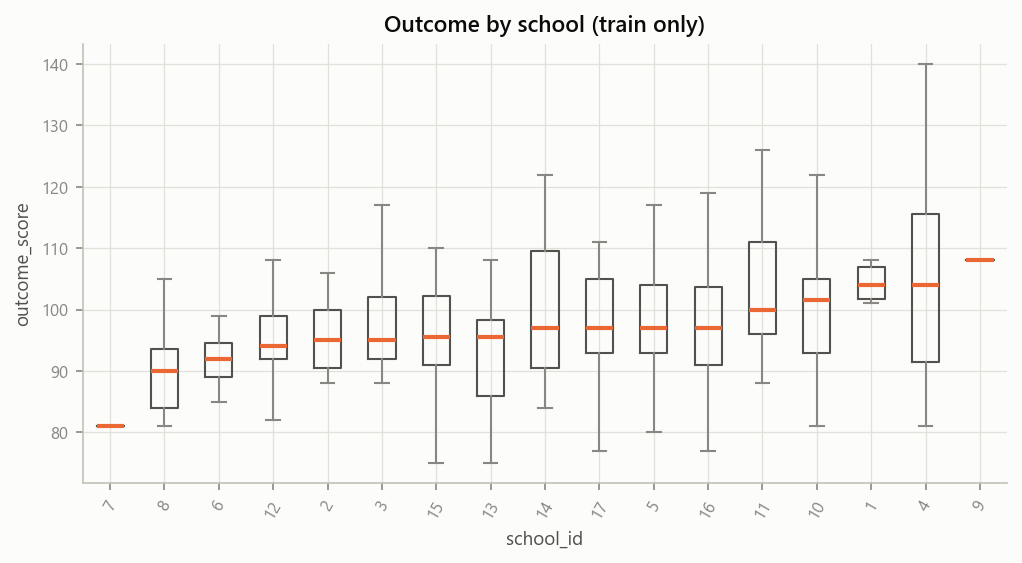

#### Tables (13 of 13)

**tabular_baselines** — 6 rows × 13 cols · *key*

,name,model,families,status,r2_mean,r2_sd,rmse_mean,mae_mean,r2_repeat_avg_pred,n_students,n_repeats,seconds,n_features_mean
0,B00_MEAN,MEAN,SCREENING,ok,-0.0004624,0.0003371,11.13,8.211,-0.0004279,541,3,4.801,12
1,B01_RIDGE_SCREENING,RIDGE,SCREENING,ok,0.1954,0.006347,9.98,7.442,0.1968,541,3,0.2884,12
2,B02_RIDGE_SCREENING_RECORDING,RIDGE,SCREENING+RECORDING,ok,0.1967,0.005896,9.972,7.392,0.1982,541,3,0.2889,14
3,B03_RIDGE_SCR_BEH_ITEM,RIDGE,SCREENING+RECORDING+BEHAVIOR+ITEM,ok,0.212,0.00806,9.877,7.278,0.2162,541,3,1.133,110
4,B04_RIDGE_TABULAR_ALL,RIDGE,SCREENING+RECORDING+BEHAVIOR+ITEM+LINGUISTIC,ok,0.2074,0.009603,9.905,7.306,0.2125,541,3,1.362,124.8
5,B05_LGBM_TABULAR_ALL,LIGHTGBM,SCREENING+RECORDING+BEHAVIOR+ITEM+LINGUISTIC,ok,0.1853,0.004482,10.04,7.467,0.2103,541,3,3.371,124.8


**target_summary** — 22 rows × 12 cols · *key*

,group_col,group,n,mean,sd,median,p05,p95,skew,kurtosis,min,max
0,all,all,541,97.91,11.14,96,82,121,1.053,2.099,64,148
1,instrument,ktea3,279,98.76,12.1,96,81,121.2,1.104,1.758,74,148
2,instrument,wj4,262,97.02,9.956,96,82,117.9,0.8197,2.047,64,132
3,original_sample_rate,11025,121,99.5,11.59,96,88,123,1.403,2.645,74,148
4,original_sample_rate,16000,420,97.46,10.97,96,81,119,0.9371,1.861,64,140
5,school_id,1,6,104.3,7.607,104,95,114,0.09844,1.135,93,116
6,school_id,10,42,101.4,9.402,101.5,91,119,0.4495,-0.05698,81,122
7,school_id,11,21,103.1,10.73,100,88,121,0.5556,-0.5499,88,126
8,school_id,12,40,97.35,11,94,85.8,121.2,1.345,1.52,80,127
9,school_id,13,24,91.96,9.388,95.5,76.05,100,-1.257,2.366,64,108


**screening_associations** — 12 rows × 9 cols · *key*

... (17 outputs left out)

**target_group_effects** — 3 rows × 5 cols

,factor,eta2,kruskal_p,icc1,n_groups
0,instrument,0.006089,0.3277,0.008447,2
1,original_sample_rate,0.005817,0.2521,0.01133,2
2,school_id,0.121,1.909e-09,0.1067,17


**theta_missingness_patterns** — 24 rows × 4 cols

,split,instrument,pattern,n
0,test,ktea3,MMo,7
1,test,ktea3,MoM,4
2,test,ktea3,Moo,3
3,test,ktea3,oMM,11
4,test,ktea3,oMo,126
5,test,ktea3,ooM,5
6,test,ktea3,ooo,31
7,test,wj4,MMo,1
8,test,wj4,Moo,4
9,test,wj4,oMo,3


In [10]:
stage('P01', key_tables=['tabular_baselines', 'target_summary', 'screening_associations', 'best_baseline_subgroups'])

---
## P02 · GPU acoustic extraction + acoustic EDA
Per-family acoustic features (quality, temporal, spectral, MFCC, mel, pitch, wavelet). Artifact screen (task / instrument / sample rate / school) and item-centred correct-vs-incorrect contrasts.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P02,cached,2026-11-20T14:12:27


### P02 · `completed` · 138.7s

,key,value
0,families,"[""quality"", ""temporal"", ""spectral"", ""mfcc"", ""m..."
1,n_clip_features,147
2,n_sig_contrasts,303
3,train_processed,14704
4,clips_per_s,114.2


#### Figures (5)

**bandlimit_by_rate**

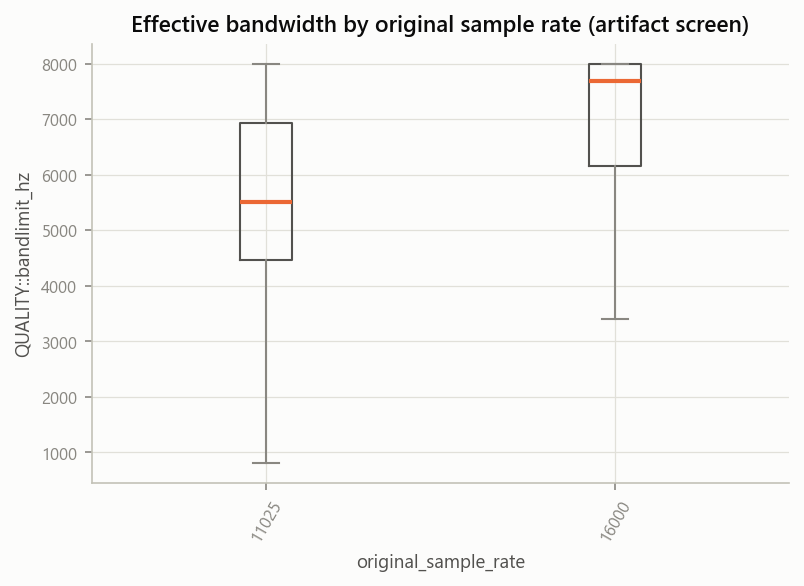

**eta2_by_factor**

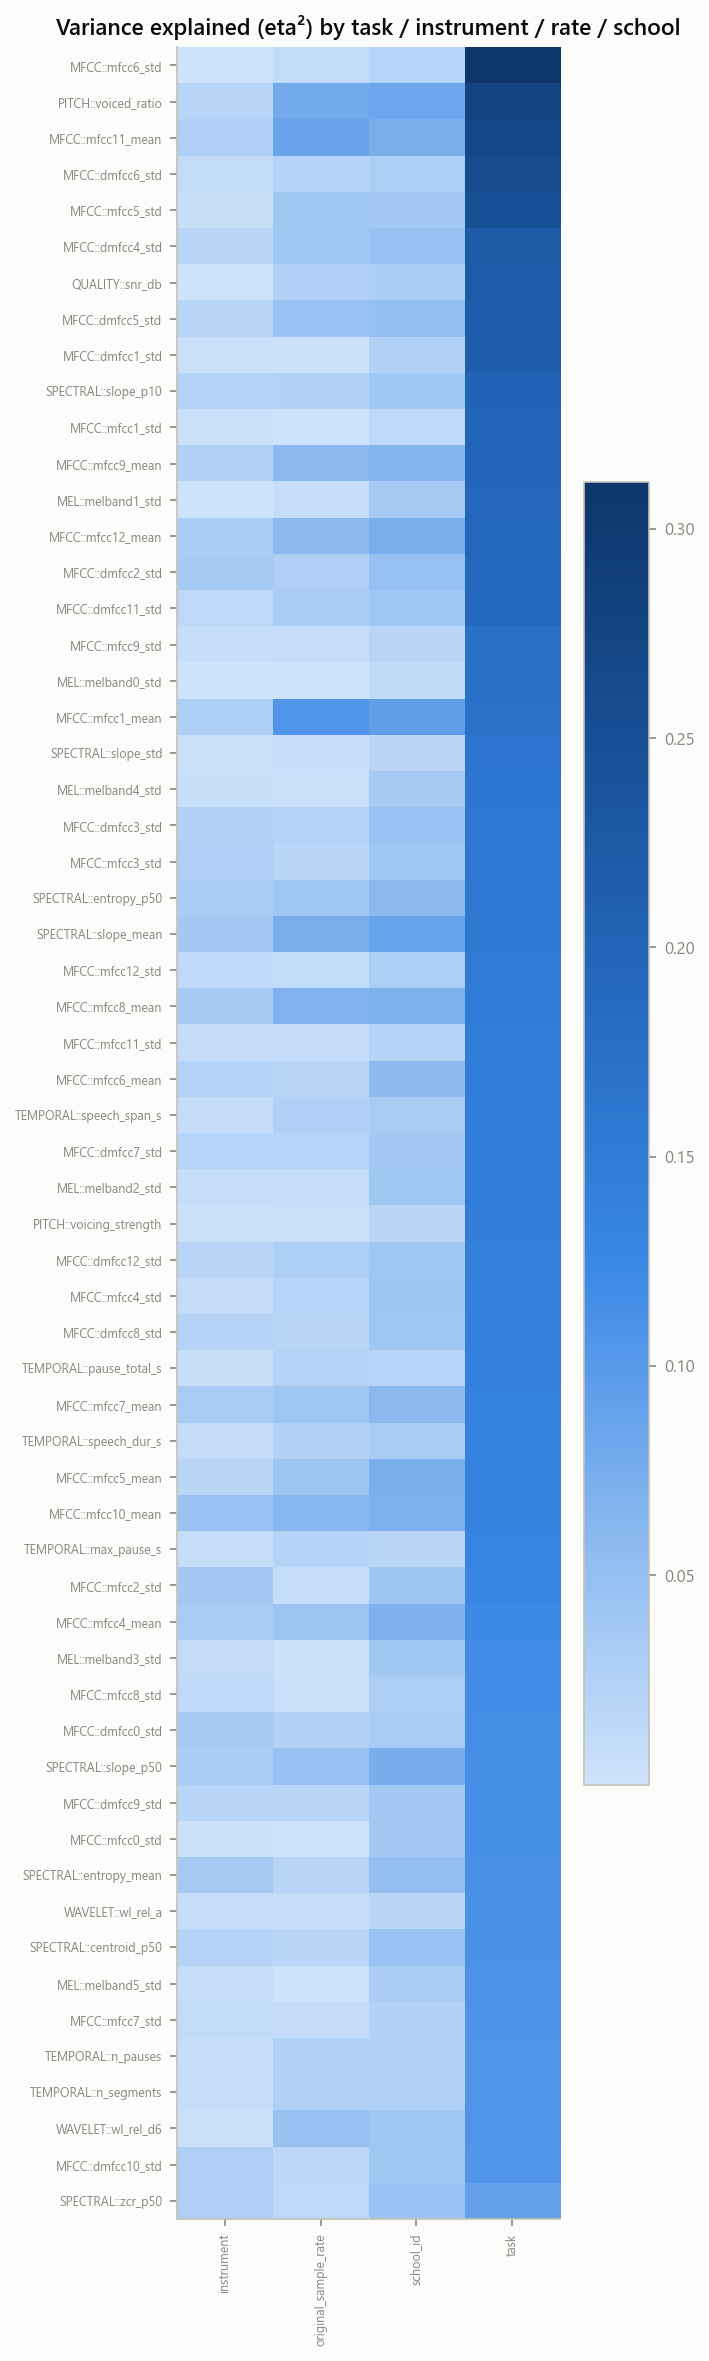

**feature_correlation**

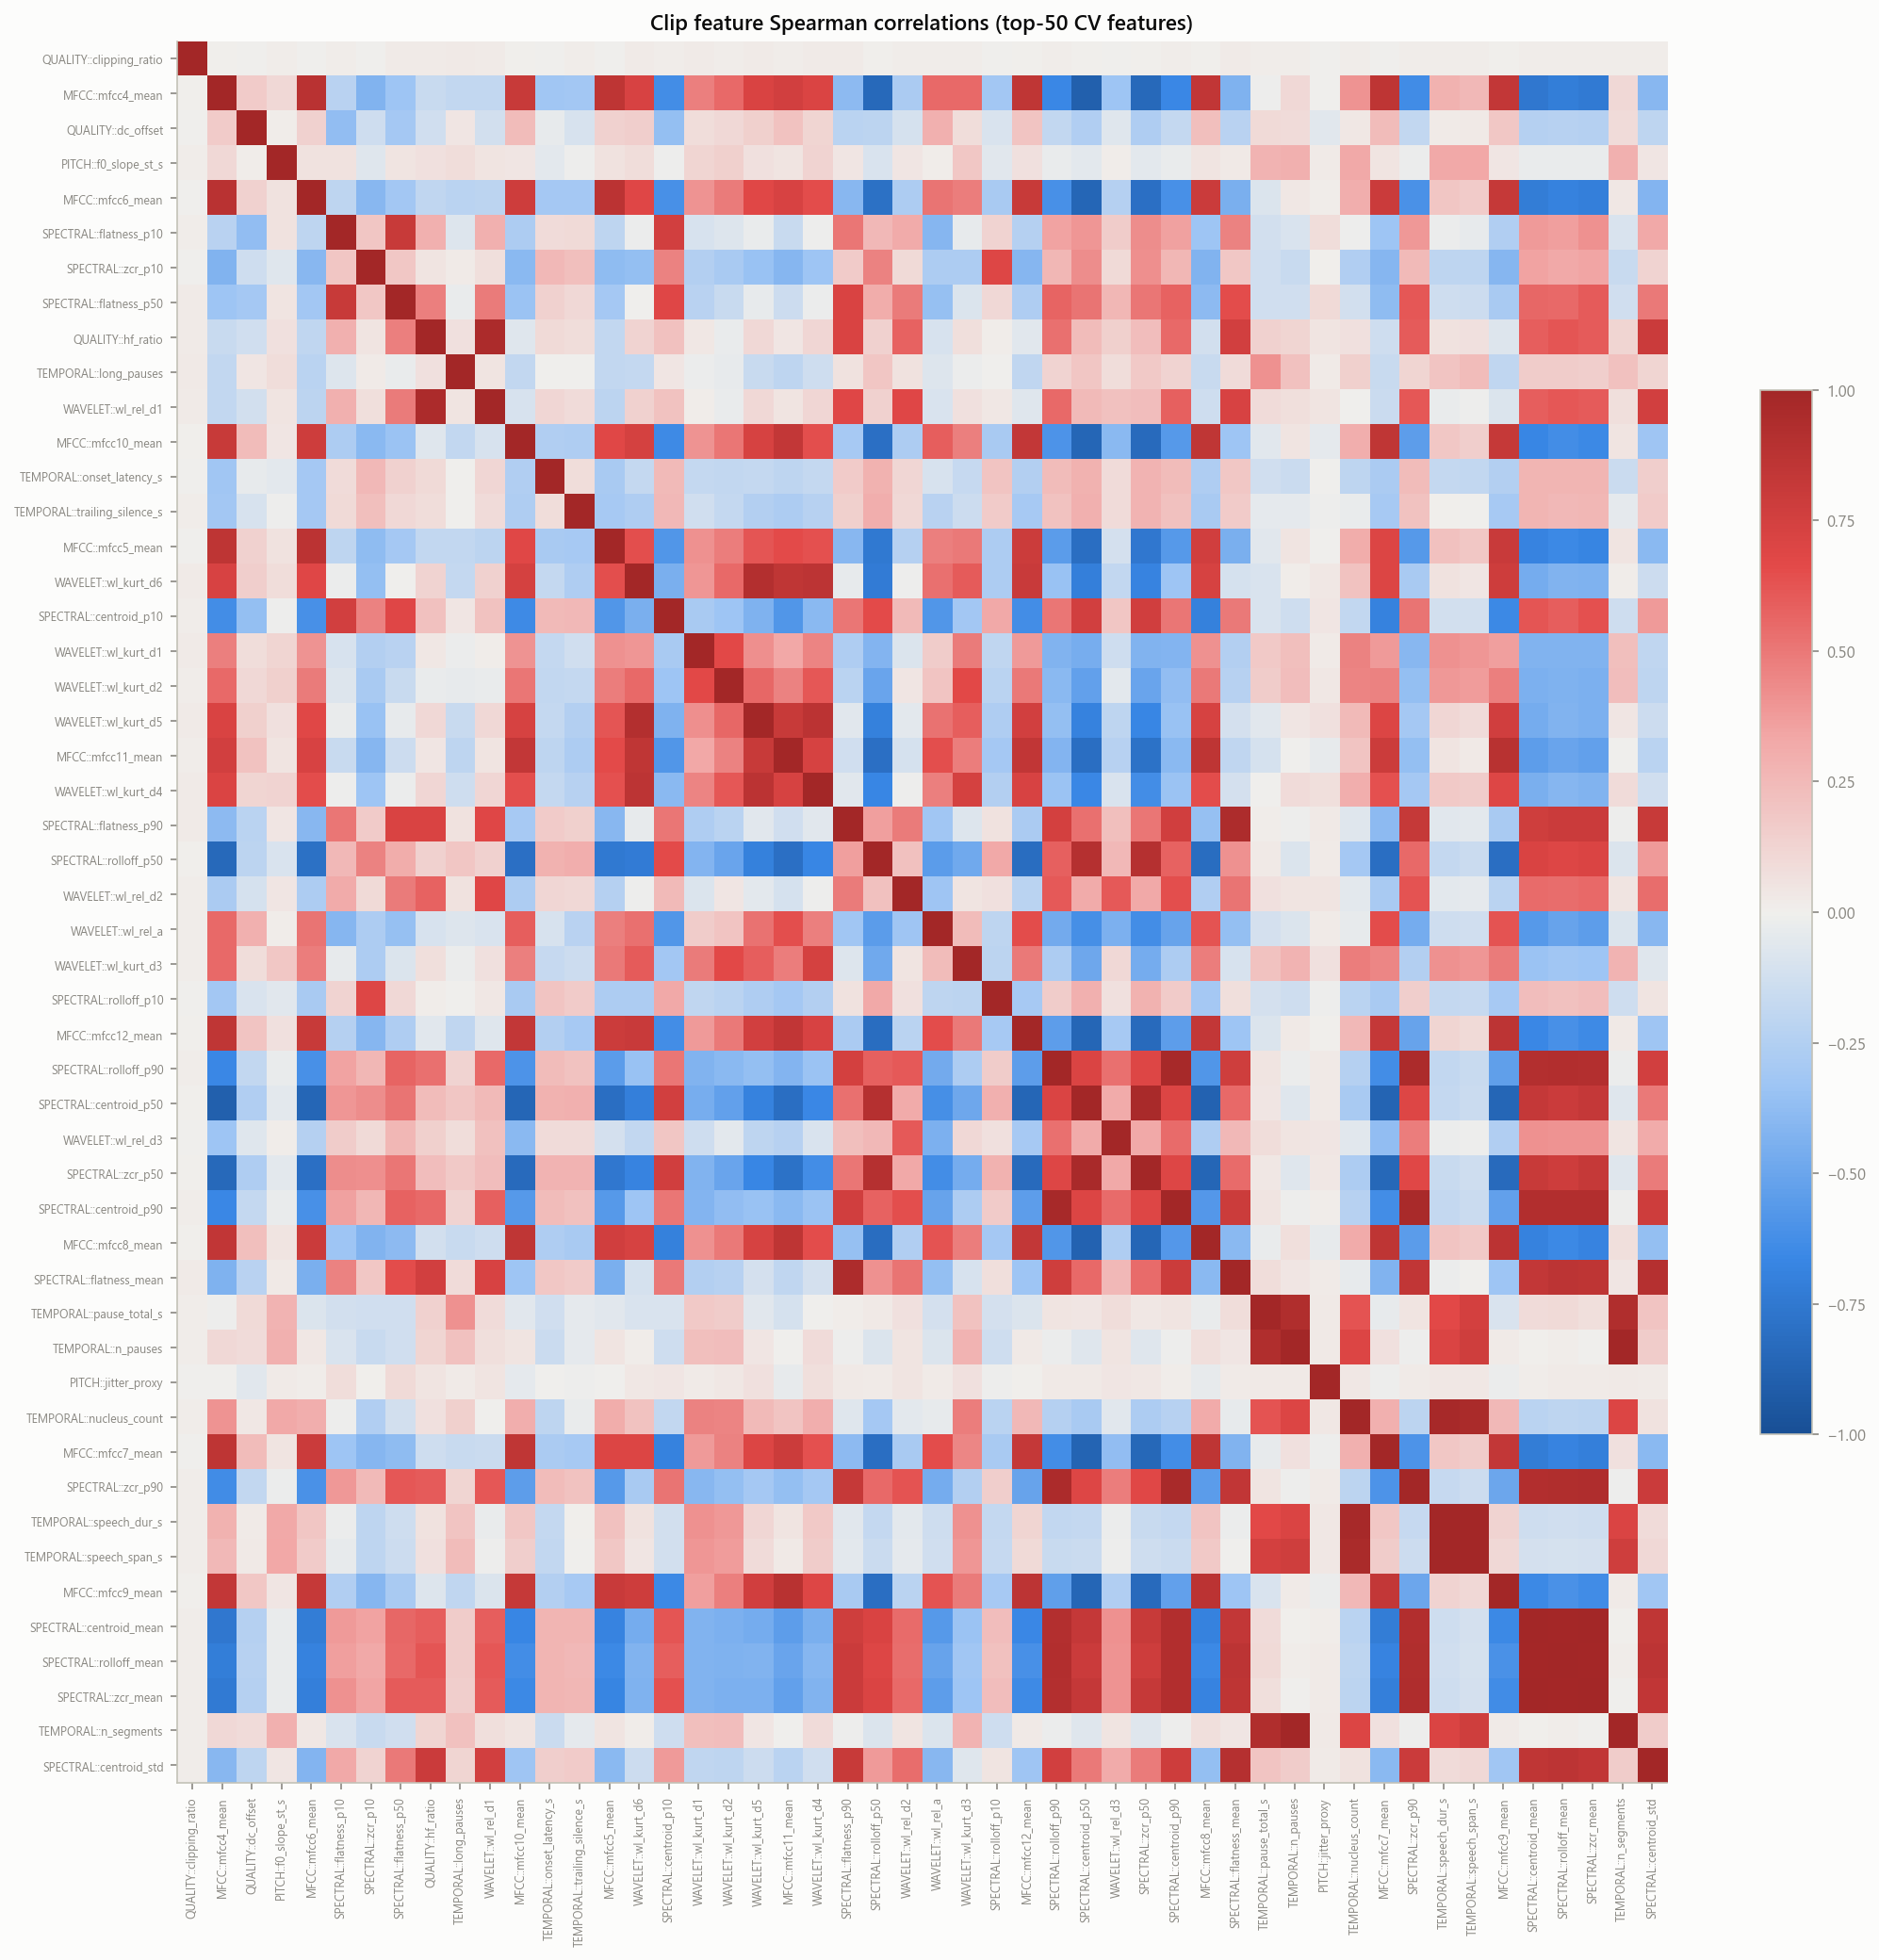

**snr_by_task**

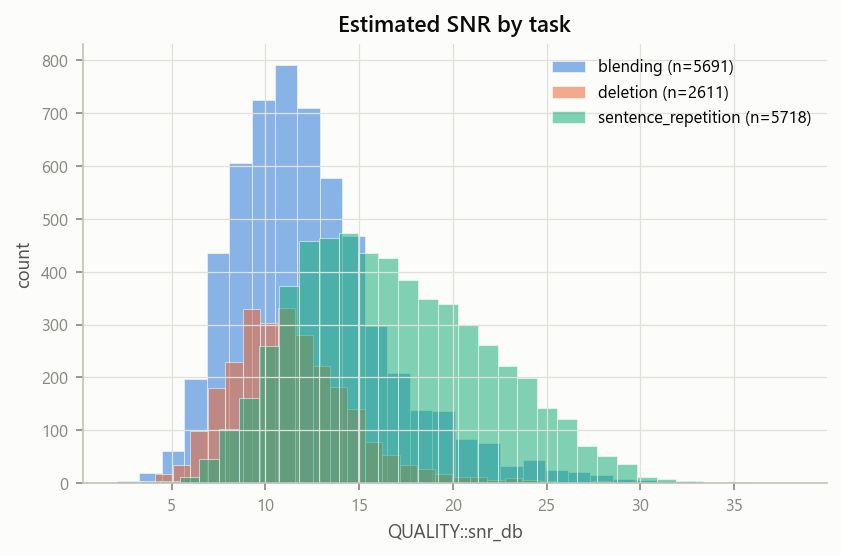

**top_correctness_contrasts**

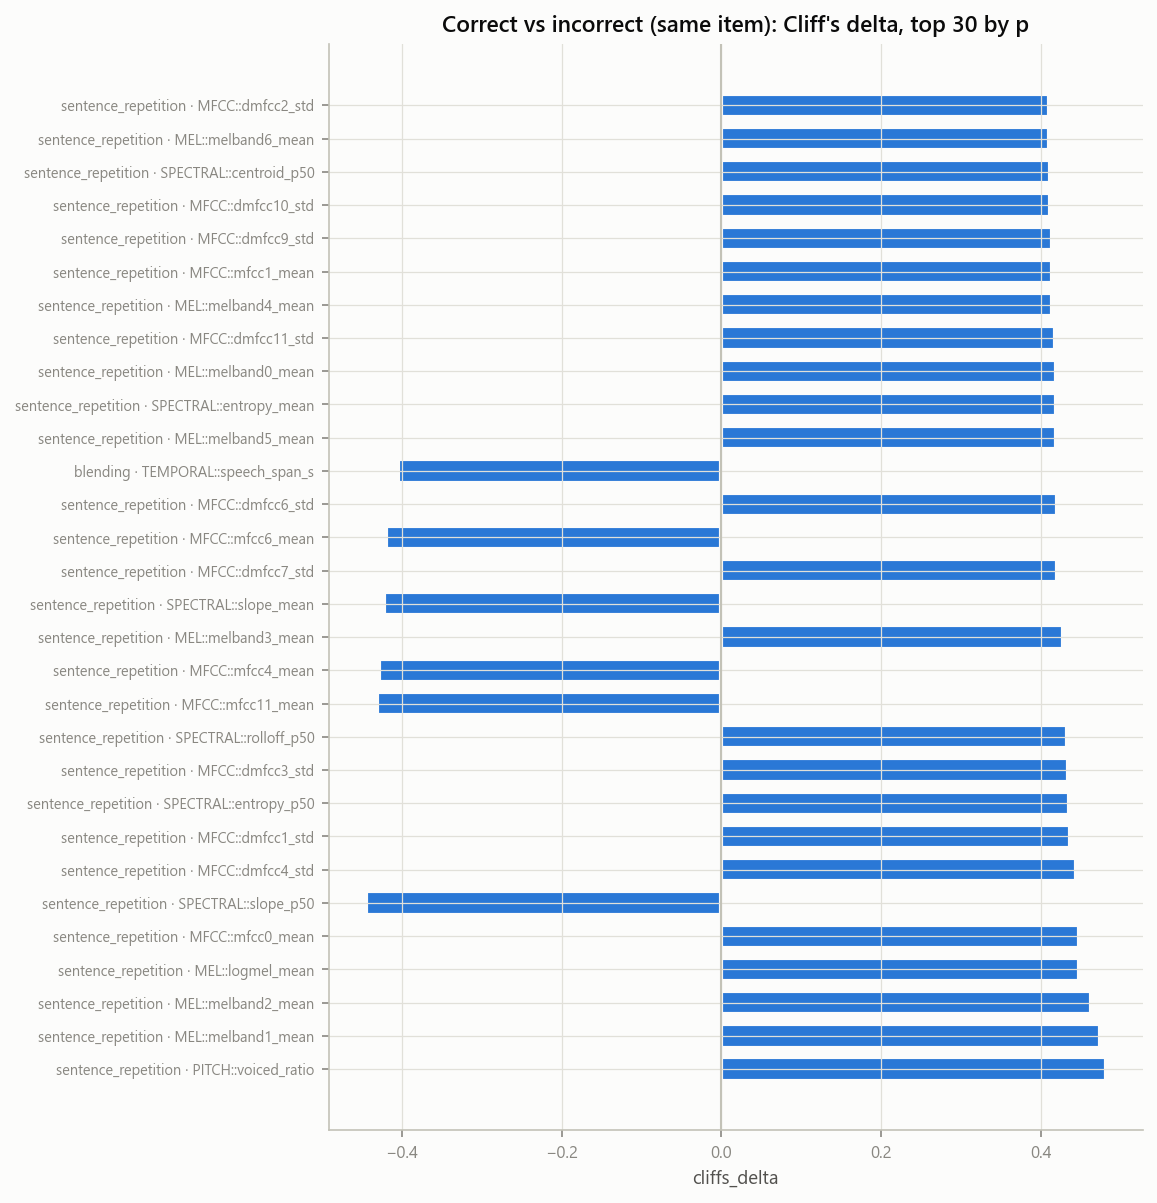

#### Tables (7 of 7)

**extraction_summary** — 1 rows × 16 cols · *key*

,split,families,requested,todo,processed,failures,seconds,clips_per_s,batch_size,max_batch_seconds,ooms,allocated_gb,reserved_gb,peak_reserved_gb,free_gb,total_gb
0,train,"['quality', 'temporal', 'spectral', 'mfcc', 'm...",14704,14704,14704,0,128.8,114.2,24,480,0,0.008595,6.113,6.113,1.281,8.589


**correctness_contrasts_item_centred** — 441 rows × 9 cols · *key*

,task,feature,n_correct,n_incorrect,diff_item_centred,std_diff,cliffs_delta,p,q
0,sentence_repetition,PITCH::voiced_ratio,2589,3136,0.1428,0.8026,0.4812,3.242e-216,1.43e-213
1,sentence_repetition,MEL::melband1_mean,2589,3136,6.79,0.7885,0.4746,2.481e-210,5.47e-208
2,sentence_repetition,MEL::melband2_mean,2589,3136,5.8,0.7671,0.4623,1.11e-199,1.632e-197
3,sentence_repetition,MEL::logmel_mean,2589,3136,3.89,0.7344,0.4481,9.655e-188,8.519e-186
4,sentence_repetition,MFCC::mfcc0_mean,2589,3136,31.12,0.7344,0.4481,9.659e-188,8.519e-186
5,sentence_repetition,SPECTRAL::slope_p50,2589,3136,-0.7619,-0.7535,-0.4448,4.502e-185,3.309e-183
6,sentence_repetition,MFCC::dmfcc4_std,2589,3136,0.4989,0.7548,0.4441,1.764e-184,1.111e-182
7,sentence_repetition,MFCC::dmfcc1_std,2589,3136,1.13,0.7449,0.437,1.097e-178,6.046e-177
8,sentence_repetition,SPECTRAL::entropy_p50,2589,3136,0.05918,0.7651,0.435,4.193e-177,2.054e-175
9,sentence_repetition,MFCC::dmfcc3_std,2589,3136,0.3718,0.7379,0.4336,6.249e-176,2.756e-174


**student_task_mean_associations** — 441 rows × 6 cols · *key*

... (5 outputs left out)

**clip_feature_summary** — 147 rows × 9 cols

,feature,n,missing_frac,mean,sd,p01,median,p99,family
0,QUALITY::snr_db,14020,0.04652,13.96,5.013,5.716,12.98,27.76,QUALITY
1,QUALITY::noise_floor_db,14704,0,-49.63,5.915,-64.52,-49.91,-36.94,QUALITY
2,QUALITY::peak_db,14704,0,-16.56,4.229,-38.85,-16.14,-11.16,QUALITY
3,QUALITY::dynamic_range_db,14704,0,33.07,6.037,18.45,33.69,44.85,QUALITY
4,QUALITY::rms_db,14704,0,-26.68,3.852,-49.76,-26.02,-26.01,QUALITY
5,QUALITY::clipping_ratio,14704,0,1.789e-09,1.571e-07,0,0,0,QUALITY
6,QUALITY::dc_offset,14704,0,-0.0005669,0.004277,-0.009804,-0.001317,0.01504,QUALITY
7,QUALITY::bandlimit_hz,14704,0,6601,1663,813.4,7250,8000,QUALITY
8,QUALITY::hf_ratio,14704,0,0.005367,0.01692,8.567e-05,0.001602,0.06257,QUALITY
9,QUALITY::low_dynamic_range,14704,0,0,0,0,0,0,QUALITY


**feature_cache_status** — 7 rows × 7 cols

,family,split,parts,rows,failures,fingerprint,bytes
0,mel,train,15,14704,0,77f13bbe56eff37e,2228558
1,mfcc,train,15,14704,0,2cc8651de355368f,4759432
2,pitch,train,15,14704,0,c2b0427a1759b2c5,1239370
3,quality,train,15,14704,0,55859e2d169586fc,1127187
4,spectral,train,15,14704,0,b30082f3f058ef38,4388745
5,temporal,train,15,14704,0,3b03c349a51fc515,1114130
6,wavelet,train,15,14704,0,eb8d6825f61d298f,2471436


In [11]:
stage('P02', key_tables=['extraction_summary', 'correctness_contrasts_item_centred', 'student_task_mean_associations', 'bandlimit_by_original_rate'])

---
## P03 · Phonetic (opt-in)
Local ASR, CTC alignment confidence, expected-text deviation. Runs only with `RUN_PHONETIC = True`.

In [12]:
stage('P03', key_tables=['phonetic_run_summary', 'phonetic_correctness_contrasts'])

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P03,disabled,phonetic.enabled


### P03 · `disabled` — phonetic.enabled=false

---
## P04 · Embeddings (opt-in)
Foundation-model embeddings. Runs only with `RUN_EMBEDDINGS = True`.

In [13]:
stage('P04', key_tables=['embedding_run_summary'])

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P04,disabled,embeddings.enabled


### P04 · `disabled` — embeddings.enabled=false

---
## P05 · Student-level features
Cross-fitted student features (each row built without that student) + feature registry.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35


### P05 · `completed` · 7.5s

,key,value
0,n_students,541
1,n_features,1564
2,families,"[""BEHAVIOR"", ""ITEM"", ""LINGUISTIC"", ""MEL"", ""MFC..."


#### Figures (1)

**features_per_family**

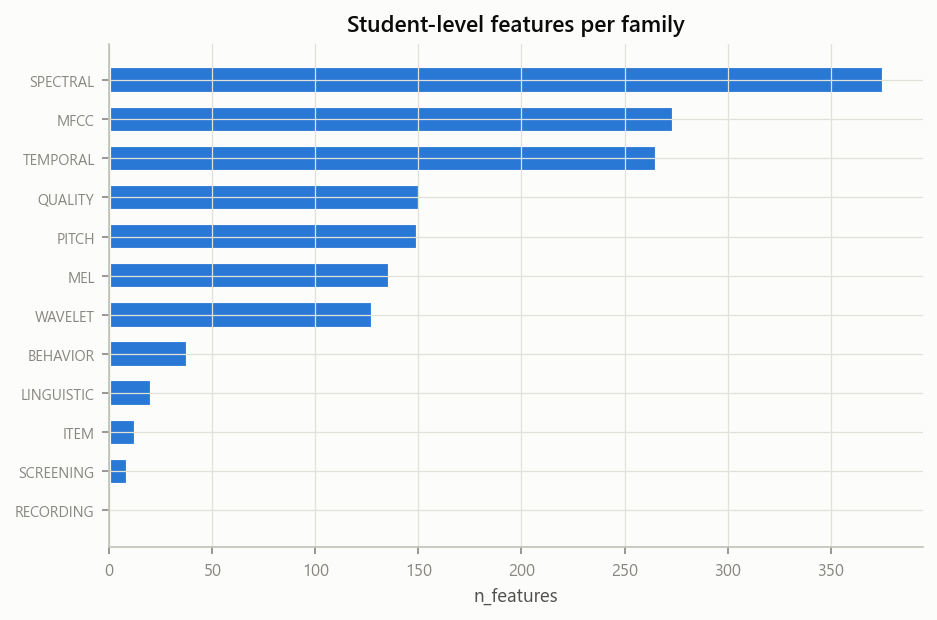

#### Tables (2 of 2)

**feature_family_summary** — 12 rows × 3 cols · *key*

,family,n_features,mean_missing
0,BEHAVIOR,38,0.1423
1,ITEM,13,0.1548
2,LINGUISTIC,21,0.1559
3,MEL,136,0.1169
4,MFCC,274,0.1331
5,PITCH,150,0.1436
6,QUALITY,151,0.1457
7,RECORDING,2,0
8,SCREENING,9,0.05566
9,SPECTRAL,376,0.1493


**feature_catalog** — 1564 rows × 10 cols · *key*

,feature,family,scope,base_feature,stat,source_stage,missing_frac,univariate_rho_outcome,univariate_p,n
0,BEHAVIOR__blending__n_items__value,BEHAVIOR,blending,n_items,value,P05,0.03697,0.1625,0.0001955,521
1,BEHAVIOR__deletion__n_items__value,BEHAVIOR,deletion,n_items,value,P05,0.3826,0.006242,0.9095,334
2,BEHAVIOR__sentence_repetition__n_items__value,BEHAVIOR,sentence_repetition,n_items,value,P05,0.04806,0.158,0.000318,515
3,BEHAVIOR__blending__n_scored__value,BEHAVIOR,blending,n_scored,value,P05,0.03697,0.1539,0.0004229,521
4,BEHAVIOR__deletion__n_scored__value,BEHAVIOR,deletion,n_scored,value,P05,0.3826,0.001062,0.9846,334
5,BEHAVIOR__sentence_repetition__n_scored__value,BEHAVIOR,sentence_repetition,n_scored,value,P05,0.04806,0.1619,0.0002253,515
6,BEHAVIOR__blending__frac_unscored__value,BEHAVIOR,blending,frac_unscored,value,P05,0.03697,-0.1136,0.00948,521
7,BEHAVIOR__deletion__frac_unscored__value,BEHAVIOR,deletion,frac_unscored,value,P05,0.3826,0.09136,0.09554,334
8,BEHAVIOR__sentence_repetition__frac_unscored__...,BEHAVIOR,sentence_repetition,frac_unscored,value,P05,0.04806,-0.09207,0.03673,515
9,BEHAVIOR__blending__accuracy__value,BEHAVIOR,blending,accuracy,value,P05,0.04067,0.4076,3.398e-22,519


In [14]:
stage('P05', key_tables=['feature_family_summary', 'feature_catalog'])

---
## P06 · Phenotypes
PCA/UMAP embedding, cluster-count selection, bootstrap stability (ARI), cluster profiles and outcome by cluster.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P06,cached,2026-11-20T14:19:09


### P06 · `completed` · 18.3s

,key,value
0,best_k,2
1,ari,0.8371
2,n_features_used,1070


#### Figures (3)

**cluster_family_profiles**

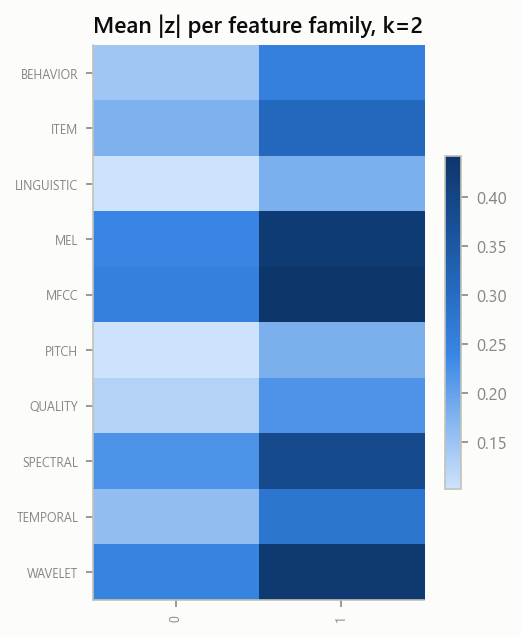

**outcome_by_cluster**

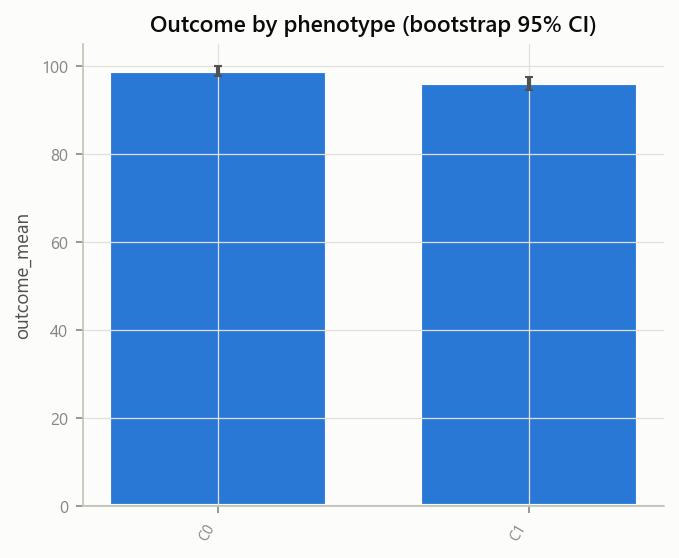

**pca_clusters**

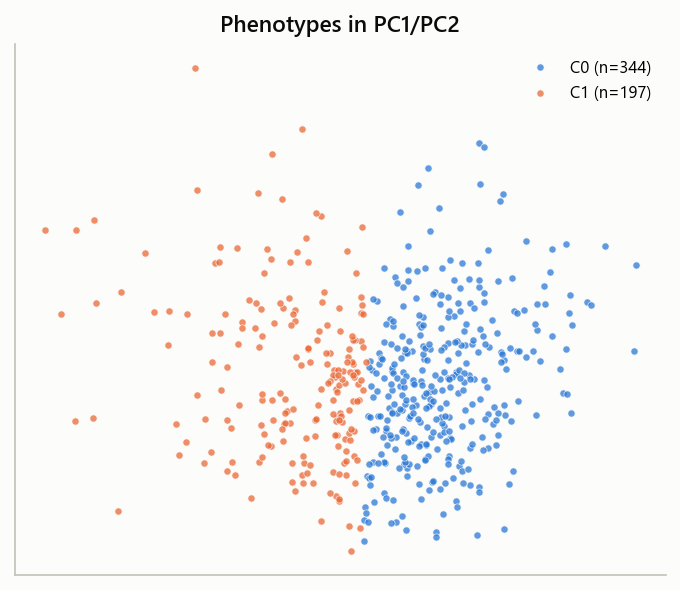

#### Tables (8 of 8)

**cluster_model_selection** — 6 rows × 7 cols · *key*

,k,kmeans_silhouette,kmeans_ch,kmeans_db,kmeans_inertia,gmm_bic,gmm_silhouette
0,2,0.1709,112.4,2.049,2.904e+05,6.364e+04,0.2226
1,3,0.111,87.31,2.253,2.65e+05,6.375e+04,0.08643
2,4,0.07856,70.17,2.431,2.522e+05,6.376e+04,-0.004567
3,5,0.07989,61.64,2.333,2.404e+05,6.389e+04,-0.0414
4,6,0.07908,56.78,2.175,2.293e+05,6.403e+04,-0.02431
5,7,0.07128,50.62,2.253,2.238e+05,6.417e+04,0.02129


**cluster_bootstrap_stability** — 6 rows × 5 cols · *key*

,k,ari_mean,ari_p05,ari_p95,n_boot
0,2,0.8371,0.5668,0.9778,50
1,3,0.7589,0.4372,0.9329,50
2,4,0.4286,0.287,0.665,50
3,5,0.4571,0.2895,0.6631,50
4,6,0.4287,0.2782,0.6884,50
5,7,0.382,0.2905,0.5204,50


**cluster_summary** — 2 rows × 10 cols · *key*

... (7 outputs left out)

**pca_loadings** — 1070 rows × 21 cols

,feature,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20
0,BEHAVIOR__blending__n_items__value,0.01478,0.01802,-0.01234,-0.02207,-0.02825,-0.01851,-0.04963,-0.01149,0.01073,0.001393,-0.06102,0.01491,0.1436,0.001877,-0.03762,-0.06014,0.04389,-0.01764,0.01236,-0.001289
1,BEHAVIOR__sentence_repetition__n_items__value,0.02287,-0.002556,-0.02384,-0.02949,0.008321,0.01617,-0.02966,0.01403,0.024,-0.02045,-0.06035,0.01475,0.1717,0.006321,0.02415,-0.009776,0.0569,-0.009995,0.01779,0.01768
2,BEHAVIOR__blending__n_scored__value,0.015,0.01805,-0.01146,-0.021,-0.02668,-0.01907,-0.05162,-0.009929,0.008104,0.0001141,-0.06269,0.01613,0.1415,0.003668,-0.03731,-0.06122,0.03903,-0.01782,0.0144,0.001032
3,BEHAVIOR__sentence_repetition__n_scored__value,0.0232,-0.00258,-0.02451,-0.02817,0.009266,0.01442,-0.03111,0.01533,0.02302,-0.02022,-0.0619,0.01569,0.1695,0.008071,0.02389,-0.01026,0.0531,-0.008388,0.01825,0.01787
4,BEHAVIOR__blending__frac_unscored__value,-0.002972,-0.002774,-0.00335,-0.003924,-0.00623,0.01213,0.02769,-0.01169,0.01328,0.00225,0.01894,-0.03149,0.004877,-0.02236,0.007938,0.0305,0.06161,0.003989,-0.0278,-0.02131
5,BEHAVIOR__sentence_repetition__frac_unscored__...,-0.008656,0.004803,0.01052,-0.004499,-0.01087,0.009287,0.0158,-0.02187,-0.001963,0.004482,0.01443,-0.01634,-0.01748,-0.02292,-0.01526,0.006024,0.01808,-0.009831,-0.01406,-0.005927
6,BEHAVIOR__blending__accuracy__value,0.02368,-0.009909,-0.03174,-0.04105,-0.04541,0.03573,-0.04812,-0.008453,-0.0002491,0.000553,-0.01874,0.03734,-0.00685,0.02932,-0.03137,0.01807,-0.03102,-0.00894,0.05614,0.02638
7,BEHAVIOR__sentence_repetition__accuracy__value,0.03368,-0.02964,-0.04675,-0.007202,-0.02057,0.02941,0.03931,0.01039,-0.008203,0.04338,-0.02724,0.01595,0.002941,-0.002294,-0.01187,0.02126,0.004876,-0.0148,-0.0103,0.01305
8,BEHAVIOR__blending__mean_difficulty__value,0.003371,-0.0158,-0.001964,0.05282,0.001488,-0.0155,-0.01035,0.03235,0.00384,-0.01471,0.009522,0.07669,-0.03539,0.06601,-0.01264,-0.0724,-0.09465,0.1089,0.04058,0.05284
9,BEHAVIOR__sentence_repetition__mean_difficulty...,0.01552,-0.015,-0.01847,0.0222,0.03178,0.0001401,-0.01093,0.04262,0.02216,-0.03188,-0.03253,0.05398,0.121,0.05159,0.0372,-0.05143,-0.007239,0.07061,0.01199,0.04614


**student_phenotype_assignments** — 541 rows × 4 cols

,subject_id,cluster,pc1,pc2
0,002067c5badc,1,-3.038,1.953
1,01a87157fa7d,1,-8.62,1.769
2,02c6ac193043,0,3.706,-0.4408
3,035deb215200,0,6.931,10.12
4,03cc329f669e,0,13.18,-12.44
5,04ab699a2376,0,2.289,0.883
6,04b3a58822bd,0,0.6581,0.9642
7,063dbecf207b,0,11.71,11.54
8,06fb45baaa44,1,-22.98,1.373
9,070ce8f34efd,0,8.914,-8.811


In [15]:
stage('P06', key_tables=['cluster_model_selection', 'cluster_bootstrap_stability', 'cluster_summary'])

---
## P07 · Residual discovery
What predicts the outcome **beyond the screening thetas**: residual associations (FDR, CIs, permutations, replication), matched comparisons, HC3-adjusted models.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P07,cached,2026-11-20T14:20:20


### P07 · `completed` · 71.3s

,key,value
0,n_features_tested,1523
1,n_q_sig,0
2,n_matched_pairs,57


#### Figures (2)

**residual_family_max_rho**

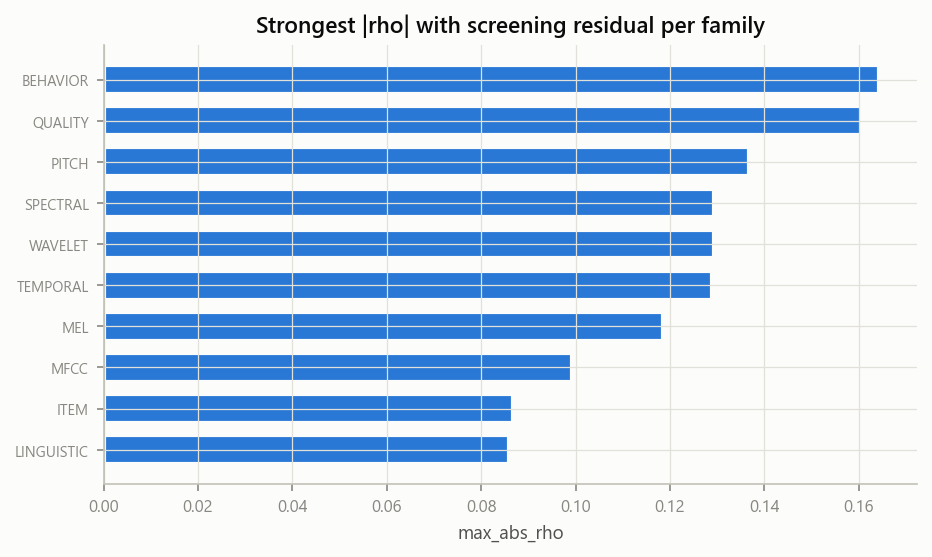

**residual_forest_top30**

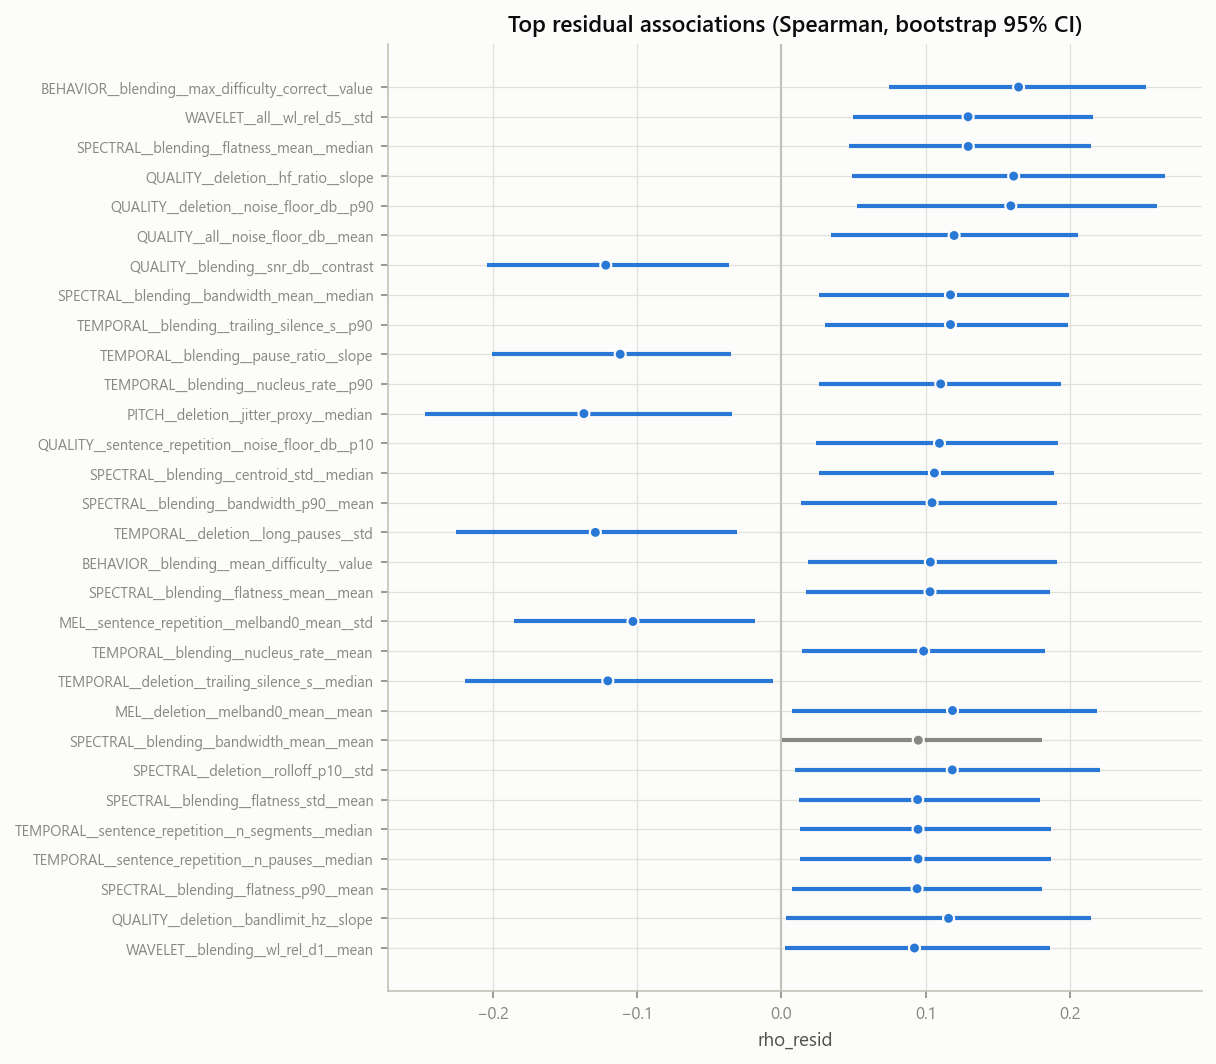

#### Tables (6 of 6)

**residual_associations** — 1523 rows × 15 cols · *key*

,feature,family,rho_resid,p_resid,n,partial_rho_outcome,p_partial,q_resid,q_partial,rho_ci_low,rho_ci_high,perm_p,times_discovered,times_replicated,replication_rate
0,BEHAVIOR__blending__max_difficulty_correct__value,BEHAVIOR,0.1642,0.0003462,471,0.1572,0.00067,0.5272,0.2551,0.07443,0.2522,0.000999,18,12,0.6667
1,WAVELET__all__wl_rel_d5__std,WAVELET,0.1292,0.002601,541,0.1113,0.009952,0.9995,0.6628,0.04956,0.2156,0.006993,8,0,0
2,SPECTRAL__blending__flatness_mean__median,SPECTRAL,0.1293,0.003106,521,0.1379,0.001708,0.9995,0.4335,0.0471,0.2141,0.005994,9,1,0.1111
3,QUALITY__deletion__hf_ratio__slope,QUALITY,0.1608,0.003215,334,0.09274,0.09359,0.9995,0.8542,0.04896,0.2655,0.004995,8,4,0.5
4,QUALITY__deletion__noise_floor_db__p90,QUALITY,0.1588,0.003618,334,0.1926,0.0004512,0.9995,0.2551,0.05263,0.26,0.003996,8,1,0.125
5,QUALITY__all__noise_floor_db__mean,QUALITY,0.1196,0.005364,541,0.1427,0.0009364,0.9995,0.2852,0.03454,0.2051,0.006993,9,0,0
6,QUALITY__blending__snr_db__contrast,QUALITY,-0.1216,0.00553,519,-0.1088,0.0137,0.9995,0.6628,-0.204,-0.03641,0.01099,13,0,0
7,SPECTRAL__blending__bandwidth_mean__median,SPECTRAL,0.117,0.007488,521,0.135,0.002132,0.9995,0.4638,0.02577,0.1993,0.008991,8,0,0
8,TEMPORAL__blending__trailing_silence_s__p90,TEMPORAL,0.117,0.007488,521,0.1183,0.00721,0.9995,0.6628,0.03001,0.1986,0.00999,5,0,0
9,TEMPORAL__blending__pause_ratio__slope,TEMPORAL,-0.1116,0.01077,521,-0.09717,0.02745,0.9995,0.7488,-0.2003,-0.03468,0.01099,9,0,0


**residual_family_summary** — 10 rows × 5 cols · *key*

,family,n_features,n_q_resid_sig,max_abs_rho,median_abs_rho
0,BEHAVIOR,37,0,0.1642,0.02102
1,QUALITY,132,0,0.1608,0.03349
2,PITCH,150,0,0.1367,0.03151
3,SPECTRAL,376,0,0.1293,0.03031
4,WAVELET,120,0,0.1292,0.03695
5,TEMPORAL,266,0,0.1288,0.03383
6,MEL,136,0,0.1184,0.03473
7,MFCC,274,0,0.09934,0.02229
8,ITEM,13,0,0.08669,0.0364
9,LINGUISTIC,19,0,0.08598,0.01792


**matched_comparisons** — 40 rows × 7 cols · *key*

... (5 outputs left out)

**screening_residuals** — 541 rows × 3 cols

,subject_id,resid,y
0,002067c5badc,4.164,104
1,01a87157fa7d,-3.426,88
2,02c6ac193043,-6.553,89
3,035deb215200,-10.97,90
4,03cc329f669e,-1.126,96
5,04ab699a2376,-7.171,91
6,04b3a58822bd,1.69,102
7,063dbecf207b,2.441,103
8,06fb45baaa44,-2.424,82
9,070ce8f34efd,-8.426,89


**screening_only_cv.json**

{
  "r2_mean": 0.19665018006881574,
  "r2_sd": 0.005896380449825564,
  "rmse_mean": 9.972057014444161,
  "mae_mean": 7.3922246086172505,
  "r2_repeat_avg_pred": 0.19823352138940697,
  "n_students": 541,
  "n_repeats": 3
}


In [16]:
stage('P07', key_tables=['residual_associations', 'residual_family_summary', 'matched_comparisons', 'adjusted_associations_hc3'])

---
## P08 · Robustness
School effects, artifact-adjusted associations, perturbation stability, domain generalisation (instrument / sample-rate transfer).

14:21:32 | INFO    | === P08 robustness — robustness
14:21:38 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged = pd.concat([old_i, fresh], axis=0).reset_index()
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retai

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P08,completed,3052.0s


### P08 · `completed` · 3052.0s

,key,value
0,school_flagged,419
1,unstable_features,115
2,domain_rows,10


#### Figures (2)

**domain_generalisation**

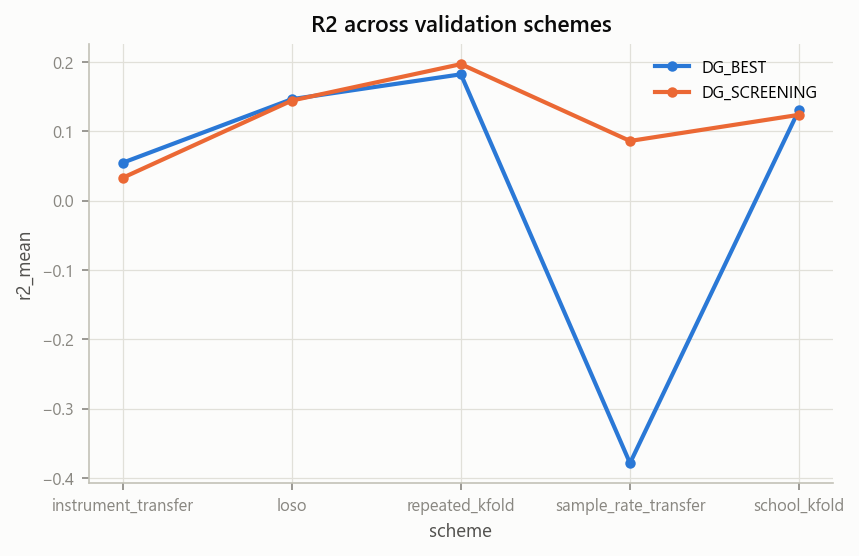

**perturbation_stability**

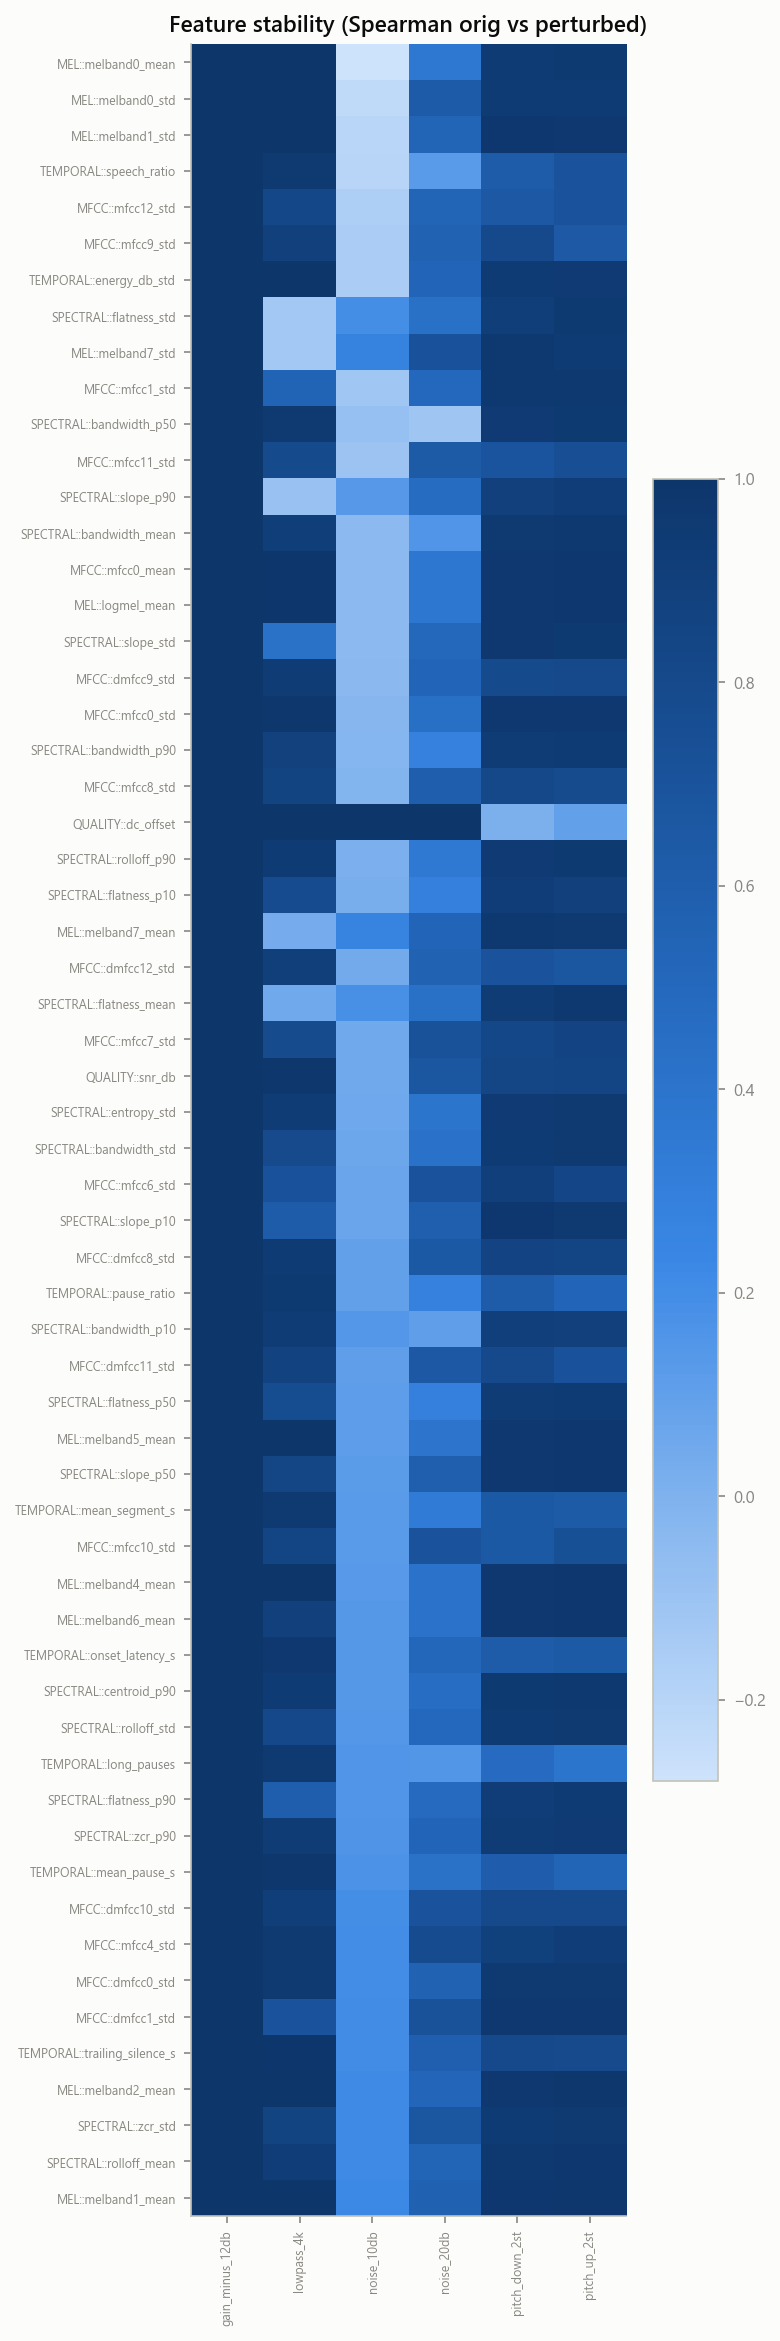

#### Tables (15 of 15)

**artifact_adjusted_associations** — 1449 rows × 6 cols · *key*

,feature,family,partial_rho_adj,p_adj,n,q_adj
0,QUALITY__all__clipping_ratio__std,QUALITY,0.1768,4.329e-05,541,0.06272
1,TEMPORAL__blending__onset_latency_s__p10,TEMPORAL,-0.1554,0.000432,521,0.313
2,WAVELET__all__wl_rel_d5__std,WAVELET,0.133,0.00218,541,0.8833
3,QUALITY__deletion__noise_floor_db__p90,QUALITY,0.1684,0.002438,334,0.8833
4,PITCH__all__jitter_proxy__mean,PITCH,-0.1151,0.008065,541,0.9927
5,WAVELET__all__wl_entropy__mean,WAVELET,-0.1147,0.008285,541,0.9927
6,PITCH__deletion__jitter_proxy__median,PITCH,-0.1454,0.008995,334,0.9927
7,WAVELET__all__wl_rel_d1__std,WAVELET,0.1116,0.01023,541,0.9927
8,PITCH__sentence_repetition__voicing_strength__std,PITCH,-0.1123,0.01174,515,0.9927
9,TEMPORAL__blending__trailing_silence_s__p90,TEMPORAL,0.1112,0.01202,521,0.9927


**perturbation_stability_summary** — 128 rows × 9 cols · *key*

,feature,gain_minus_12db,lowpass_4k,noise_10db,noise_20db,pitch_down_2st,pitch_up_2st,min_stability,family
0,MEL::melband0_mean,1,0.9942,-0.2803,0.3639,0.9386,0.9522,-0.2803,MEL
1,MEL::melband0_std,1,0.9978,-0.2267,0.6318,0.9379,0.9376,-0.2267,MEL
2,MEL::melband1_std,1,0.9962,-0.2065,0.5359,0.9759,0.9654,-0.2065,MEL
3,TEMPORAL::speech_ratio,1,0.9592,-0.2042,0.12,0.6176,0.6964,-0.2042,TEMPORAL
4,MFCC::mfcc12_std,0.9999,0.8165,-0.1702,0.5346,0.6531,0.6994,-0.1702,MFCC
5,MFCC::mfcc9_std,0.9999,0.892,-0.1579,0.5587,0.804,0.643,-0.1579,MFCC
6,TEMPORAL::energy_db_std,1,0.9936,-0.1514,0.529,0.9443,0.9471,-0.1514,TEMPORAL
7,SPECTRAL::flatness_std,1,-0.133,0.1943,0.432,0.9076,0.9516,-0.133,SPECTRAL
8,MEL::melband7_std,1,-0.1274,0.2739,0.7072,0.9604,0.9427,-0.1274,MEL
9,MFCC::mfcc1_std,0.9999,0.5471,-0.1174,0.4994,0.9642,0.9628,-0.1174,MFCC


**domain_generalisation** — 10 rows × 13 cols · *key*

... (21 outputs left out)

**school_adjusted_residual_associations** — 1523 rows × 10 cols

,feature,family,rho_raw,p_raw,rho_school_demeaned,p_school_demeaned,n,sign_kept,q_raw,q_school_demeaned
0,SPECTRAL__blending__flatness_mean__median,SPECTRAL,0.1293,0.003106,0.1348,0.002038,521,True,0.9995,0.9807
1,WAVELET__all__wl_rel_d5__std,WAVELET,0.1292,0.002601,0.1274,0.002983,541,True,0.9995,0.9807
2,SPECTRAL__blending__bandwidth_mean__median,SPECTRAL,0.117,0.007488,0.1244,0.004464,521,True,0.9995,0.9807
3,QUALITY__deletion__hf_ratio__slope,QUALITY,0.1608,0.003215,0.1529,0.005113,334,True,0.9995,0.9807
4,PITCH__sentence_repetition__f0_range_st__contrast,PITCH,-0.0919,0.03708,-0.123,0.005178,515,True,0.9995,0.9807
5,TEMPORAL__blending__pause_ratio__slope,TEMPORAL,-0.1116,0.01077,-0.122,0.005287,521,True,0.9995,0.9807
6,MEL__deletion__melband0_mean__mean,MEL,0.1184,0.03046,0.1503,0.005921,334,True,0.9995,0.9807
7,TEMPORAL__blending__trailing_silence_s__p90,TEMPORAL,0.117,0.007488,0.1193,0.006395,521,True,0.9995,0.9807
8,QUALITY__deletion__noise_floor_db__p90,QUALITY,0.1588,0.003618,0.1405,0.01015,334,True,0.9995,0.9807
9,BEHAVIOR__blending__max_difficulty_correct__value,BEHAVIOR,0.1642,0.0003462,0.1173,0.01082,471,True,0.5272,0.9807


**school_effects** — 1523 rows × 7 cols

,feature,family,school_eta2,kruskal_p,icc1,q,school_flag
0,LINGUISTIC__sentence_repetition__n_phonemes__mean,LINGUISTIC,0.5328,7.525e-49,0.5555,5.731e-46,True
1,LINGUISTIC__sentence_repetition__n_syllables__...,LINGUISTIC,0.5313,2.275e-42,0.5539,3.849e-40,True
2,BEHAVIOR__blending__mean_difficulty__value,BEHAVIOR,0.5005,1.165e-37,0.5213,1.613e-35,True
3,BEHAVIOR__all__n_tasks__value,BEHAVIOR,0.4951,1.936e-49,0.5144,2.949e-46,True
4,LINGUISTIC__blending__max_cluster__mean,LINGUISTIC,0.481,4.147e-47,0.5012,2.105e-44,True
5,LINGUISTIC__sentence_repetition__mean_word_len...,LINGUISTIC,0.4734,7.879e-30,0.4946,6.667e-28,True
6,LINGUISTIC__sentence_repetition__n_words__mean,LINGUISTIC,0.4671,1.004e-40,0.488,1.529e-38,True
7,BEHAVIOR__sentence_repetition__total_duration_...,BEHAVIOR,0.4476,2.336e-27,0.4677,1.617e-25,True
8,TEMPORAL__blending__long_pauses__p10,TEMPORAL,0.4394,2.582e-33,0.4579,3.025e-31,True
9,BEHAVIOR__sentence_repetition__n_items__value,BEHAVIOR,0.4295,1.303e-44,0.4488,3.307e-42,True


In [17]:
stage('P08', key_tables=['artifact_adjusted_associations', 'perturbation_stability_summary', 'domain_generalisation'])

---
## P09 · Literacy indices (experimental)
Composite indices: incremental R² with CIs, Cronbach α, split-half reliability. Experimental constructs, not diagnoses.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P09,cached,2026-11-20T15:12:34


### P09 · `completed` · 11.4s

,key,value
0,n_indices,4
1,best,PHONOLOGICAL_PRECISION


#### Figures (1)

**index_incremental_r2**

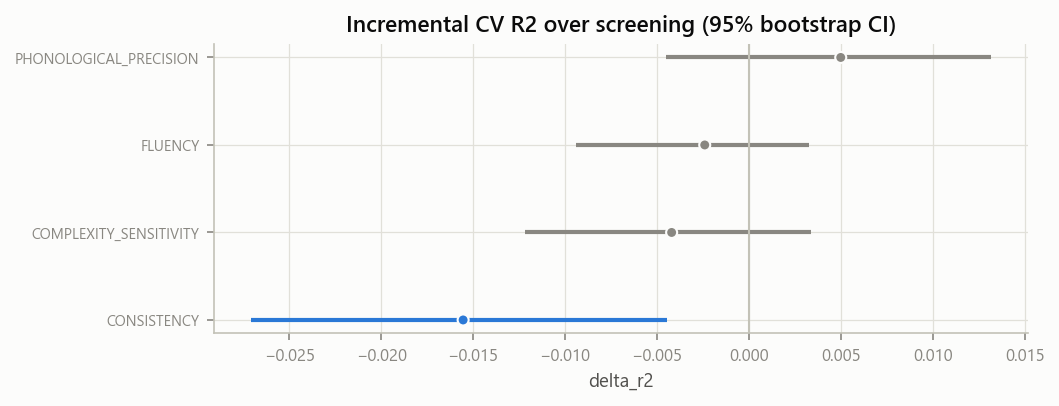

#### Tables (5 of 5)

**index_validation** — 4 rows × 12 cols · *key*

,index,status,description,delta_r2,ci_low,ci_high,cronbach_alpha_mean,n_components_mean,sign_stability,split_half_r,spearman_brown,n_components
0,PHONOLOGICAL_PRECISION,ok,Difficulty-adjusted accuracy and pronunciation...,0.004995,-0.004488,0.01316,-1.102,2,1,0.3717,0.542,2
1,FLUENCY,ok,"Speech-rate, latency and pause structure on se...",-0.002401,-0.009391,0.00328,0.2727,6,0.8889,0.2204,0.3612,6
2,CONSISTENCY,ok,Within-student variability of timing and spect...,-0.01554,-0.02707,-0.004459,0.1656,16,0.6083,0.2185,0.3587,16
3,COMPLEXITY_SENSITIVITY,ok,How strongly timing and accuracy degrade with ...,-0.004201,-0.0122,0.003362,0.3352,9,0.6148,0.09104,0.1669,9


**index_components_COMPLEXITY_SENSITIVITY** — 15 rows × 13 cols

,repeat,fold,n_components,alpha,sign__TEMPORAL__blending__speech_dur_s__slope,sign__TEMPORAL__deletion__speech_dur_s__slope,sign__TEMPORAL__sentence_repetition__speech_dur_s__slope,sign__TEMPORAL__blending__onset_latency_s__slope,sign__TEMPORAL__deletion__onset_latency_s__slope,sign__TEMPORAL__sentence_repetition__onset_latency_s__slope,sign__BEHAVIOR__blending__duration_z__slope,sign__BEHAVIOR__deletion__duration_z__slope,sign__BEHAVIOR__sentence_repetition__duration_z__slope
0,0,0,9,0.2505,1,1,-1,-1,-1,1,-1,1,-1
1,0,1,9,0.4668,1,1,-1,-1,-1,-1,1,1,-1
2,0,2,9,0.4906,1,1,-1,-1,-1,1,1,1,-1
3,0,3,9,0.1817,1,1,-1,1,1,1,-1,1,-1
4,0,4,9,0.451,-1,1,-1,-1,-1,1,-1,1,-1
5,1,0,9,0.4336,1,1,-1,-1,-1,1,1,1,-1
6,1,1,9,0.3947,1,1,-1,1,-1,-1,1,1,-1
7,1,2,9,0.1424,1,1,-1,-1,1,-1,-1,1,-1
8,1,3,9,0.4453,1,1,-1,-1,-1,-1,1,1,-1
9,1,4,9,0.4513,-1,1,-1,1,1,1,-1,1,-1


**index_components_CONSISTENCY** — 15 rows × 20 cols

... (3 outputs left out)

**index_components_PHONOLOGICAL_PRECISION** — 15 rows × 6 cols

,repeat,fold,n_components,alpha,sign__ITEM__blending__adj_accuracy,sign__ITEM__deletion__adj_accuracy
0,0,0,2,-1.125,1,-1
1,0,1,2,-1.102,1,-1
2,0,2,2,-1.148,1,-1
3,0,3,2,-0.9664,1,-1
4,0,4,2,-1.146,1,-1
5,1,0,2,-1.026,1,-1
6,1,1,2,-1.067,1,-1
7,1,2,2,-1.189,1,-1
8,1,3,2,-1.154,1,-1
9,1,4,2,-1.096,1,-1


**DISCLAIMER.json**

{
  "disclaimer": "Indices are experimental measurement constructs derived from anonymised assessment audio. They are not established educational or clinical diagnoses and must not be used to label students."
}


In [18]:
stage('P09', key_tables=['index_validation'])

---
## P10 · Model benchmark + ablations
Model × feature-family grid and budgeted family ablations with paired ΔR² CIs.

15:13:53 | INFO    | === P10 model_benchmark — model benchmark + family ablations
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = oof.groupby("repeat").apply(lambda d: pd.Series(metric_row(d["y_true"], d["y_pred"])))
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns af

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P10,completed,912.2s


### P10 · `completed` · 912.2s

,key,value
0,n_models,35
1,best,B_GAM__SCREENING+BEHAVIOR+ITEM
2,best_r2,0.2153
3,ablation_evals,80


#### Figures (2)

**ablation_single_add**

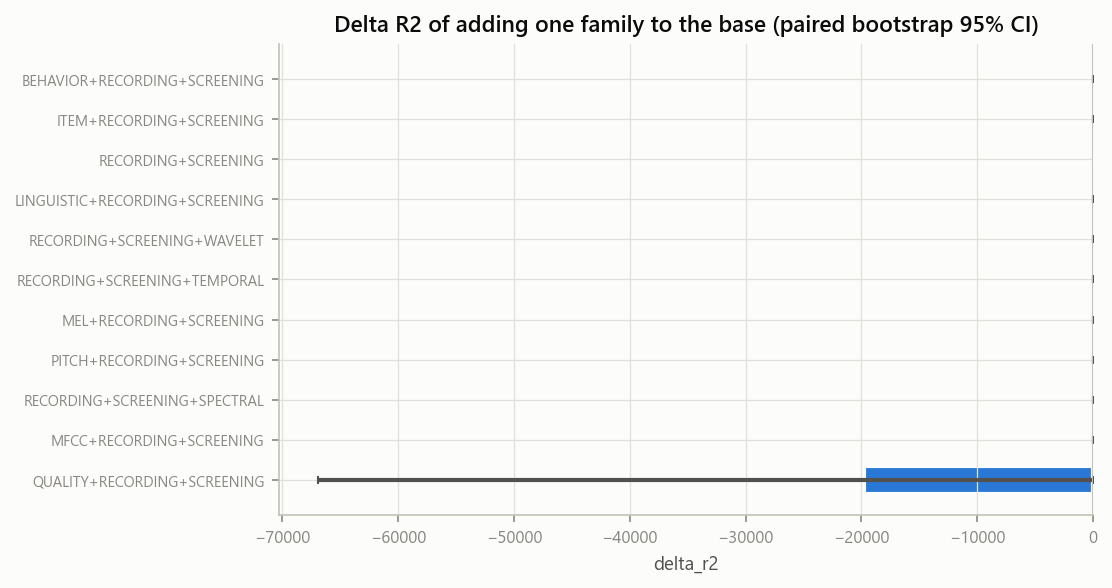

**benchmark_heatmap**

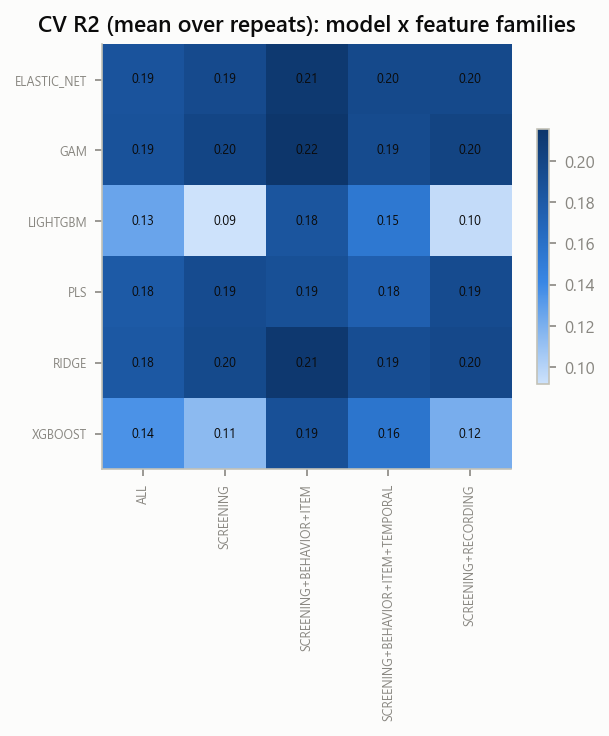

#### Tables (3 of 3)

**model_benchmark** — 35 rows × 18 cols · *key*

,name,model,families,status,r2_mean,r2_sd,rmse_mean,mae_mean,r2_repeat_avg_pred,n_students,n_repeats,seconds,n_features_mean,delta_r2,delta_ci_low,delta_ci_high,delta_r2_repeat_mean,delta_r2_repeat_min
0,B_RIDGE__SCREENING,RIDGE,SCREENING,ok,0.1954,0.006347,9.98,7.442,0.1968,541,3,0.2994,12,-0.001401,-0.009201,0.005898,-0.001242,-0.001867
1,B_RIDGE__SCREENING+RECORDING,RIDGE,SCREENING+RECORDING,ok,0.1967,0.005896,9.972,7.392,0.1982,541,3,0.35,14,NaN,NaN,NaN,NaN,NaN
2,B_RIDGE__SCREENING+BEHAVIOR+ITEM,RIDGE,SCREENING+BEHAVIOR+ITEM,ok,0.2124,0.008279,9.874,7.277,0.2166,541,3,1.141,108,0.01839,-0.005651,0.04172,0.01575,0.01261
3,B_RIDGE__SCREENING+BEHAVIOR+ITEM+TEMPORAL,RIDGE,SCREENING+BEHAVIOR+ITEM+TEMPORAL,ok,0.1916,0.005801,10,7.355,0.1973,541,3,4.855,200,-0.000917,-0.02781,0.02783,-0.00503,-0.01462
4,B_RIDGE__ALL,RIDGE,ALL,ok,0.182,0.002441,10.06,7.494,0.1892,541,3,21.87,200,-0.009075,-0.03853,0.01885,-0.01468,-0.02098
5,B_ELASTIC_NET__SCREENING,ELASTIC_NET,SCREENING,ok,0.1946,0.005818,9.985,7.444,0.1962,541,3,1.252,12,-0.002022,-0.009696,0.005153,-0.002064,-0.002997
6,B_ELASTIC_NET__SCREENING+RECORDING,ELASTIC_NET,SCREENING+RECORDING,ok,0.1959,0.005017,9.977,7.398,0.1976,541,3,1.169,14,-0.0005995,-0.002101,0.0008502,-0.0007443,-0.001372
7,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,ELASTIC_NET,SCREENING+BEHAVIOR+ITEM,ok,0.2119,0.007338,9.877,7.3,0.2151,541,3,6.692,108,0.01687,-0.006334,0.04015,0.01521,0.01317
8,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM+TEMPORAL,ELASTIC_NET,SCREENING+BEHAVIOR+ITEM+TEMPORAL,ok,0.1961,0.005163,9.976,7.358,0.2024,541,3,32.76,200,0.004193,-0.02142,0.03124,-0.0005697,-0.01174
9,B_ELASTIC_NET__ALL,ELASTIC_NET,ALL,ok,0.1859,0.004157,10.04,7.444,0.191,541,3,125.5,200,-0.007229,-0.03448,0.02106,-0.0108,-0.02062


**family_ablation** — 80 rows × 20 cols · *key*

,families,n_families,kind,r2_mean,r2_sd,rmse_mean,mae_mean,r2_repeat_avg_pred,n_students,n_repeats,seconds,n_features_mean,delta_r2,delta_ci_low,delta_ci_high,delta_r2_repeat_mean,delta_r2_repeat_min,forward_path,evals_used,budget_exhausted
0,BEHAVIOR+RECORDING+SCREENING,3,single_add,0.2147,0.01325,9.859,7.266,0.2202,541,3,0.9602,85,0.02196,-0.006041,0.04517,0.018,0.007605,SCREENING+RECORDING+BEHAVIOR,80,True
1,BEHAVIOR+ITEM+RECORDING+SCREENING,4,forward,0.212,0.00806,9.877,7.278,0.2162,541,3,1.174,110,0.01795,-0.008255,0.0407,0.01531,0.01246,SCREENING+RECORDING+BEHAVIOR,80,True
2,BEHAVIOR+LINGUISTIC+RECORDING+SCREENING,4,forward,0.2066,0.01946,9.91,7.324,0.2136,541,3,1.326,117.8,0.01541,-0.01512,0.04251,0.009924,-0.009259,SCREENING+RECORDING+BEHAVIOR,80,True
3,BEHAVIOR+ITEM+LINGUISTIC+RECORDING+SCREENING,5,subset_3,0.2036,0.01202,9.928,7.336,0.2096,541,3,1.41,130.8,0.01138,-0.01807,0.03791,0.006998,-0.001647,SCREENING+RECORDING+BEHAVIOR,80,True
4,ITEM+RECORDING+SCREENING,3,single_add,0.1989,0.002942,9.958,7.354,0.2014,541,3,0.5318,39,0.00317,-0.01532,0.01835,0.002288,-0.0003935,SCREENING+RECORDING+BEHAVIOR,80,True
5,ITEM+LINGUISTIC+RECORDING+SCREENING,4,subset_2,0.1984,0.002306,9.961,7.386,0.2018,541,3,0.8758,76.6,0.003547,-0.0179,0.02295,0.001792,-0.002365,SCREENING+RECORDING+BEHAVIOR,80,True
6,RECORDING+SCREENING,2,base,0.1967,0.005896,9.972,7.392,0.1982,541,3,0.3662,14,0,NaN,NaN,NaN,NaN,SCREENING+RECORDING+BEHAVIOR,80,True
7,BEHAVIOR+ITEM+RECORDING+SCREENING+WAVELET,5,subset_3,0.1928,0.002969,9.996,7.441,0.1992,541,3,3.125,200,0.001001,-0.02982,0.02689,-0.00383,-0.007482,SCREENING+RECORDING+BEHAVIOR,80,True
8,BEHAVIOR+ITEM+RECORDING+SCREENING+TEMPORAL,5,subset_3,0.191,0.005111,10.01,7.354,0.1973,541,3,4.885,200,-0.0009786,-0.02964,0.03007,-0.005685,-0.01416,SCREENING+RECORDING+BEHAVIOR,80,True
9,BEHAVIOR+RECORDING+SCREENING+WAVELET,4,forward,0.1887,0.00806,10.02,7.466,0.1965,541,3,3.218,200,-0.001781,-0.03489,0.02739,-0.007912,-0.01062,SCREENING+RECORDING+BEHAVIOR,80,True


**best_model_subgroups** — 23 rows × 8 cols · *key*

,group_col,group,r2,rmse,mae,n,pearson,bias
0,instrument,ktea3,0.2164,10.69,7.922,279,0.4663,-0.1981
1,instrument,wj4,0.2097,8.834,6.595,262,0.4583,0.1982
2,original_sample_rate,11025,0.1997,10.32,7.673,121,0.4585,0.06601
3,original_sample_rate,16000,0.2185,9.69,7.166,420,0.4675,-0.02701
4,school_id,1,-1.274,10.47,5.899,6,-0.1656,-3.177
5,school_id,10,-0.002278,9.3,7.935,42,0.248,-0.4582
6,school_id,11,-0.03612,10.66,7.688,21,0.2626,-3.12
7,school_id,12,0.2483,9.421,7.55,40,0.5114,0.6609
8,school_id,13,0.1451,8.497,6.304,24,0.5171,3.156
9,school_id,15,0.3598,7.113,5.78,22,0.6846,-0.8437


**available_families.json**

{
  "available_families": [
    "BEHAVIOR",
    "ITEM",
    "LINGUISTIC",
    "MEL",
    "MFCC",
    "PITCH",
    "QUALITY",
    "RECORDING",
    "SCREENING",
    "SPECTRAL",
    "TEMPORAL",
    "WAVELET"
  ]
}


In [19]:
stage('P10', key_tables=['model_benchmark', 'family_ablation', 'best_model_subgroups'])

---
## P11 · Multimodal fusion
Late fusion, task ensembles, residual stacking, MoE (+ neural MIL in RESEARCH).

In [20]:
stage('P11', key_tables=['multimodal_results'])

15:29:27 | INFO    | === P11 multimodal — fusion, residual learning, neural MIL / transformer / MoE
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = oof.groupby("repeat").apply(lambda d: pd.Series(metric_row(d["y_true"], d["y_pred"])))
c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 9.068422317504883, tolerance: 4.015555381774902
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\sklearn\line

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P10,cached,2026-11-20T15:29:06
4,P11,completed,271.8s


### P11 · `completed` · 271.8s

,key,value
0,n_models,6
1,best,F_LATE_FAMILY_RIDGE


#### Tables (1 of 1)

**multimodal_results** — 6 rows × 18 cols · *key*

,name,model,deployable,status,r2_mean,r2_sd,rmse_mean,mae_mean,r2_repeat_avg_pred,n_students,n_repeats,seconds,n_features_mean,vs_best_p10_delta_r2,vs_best_p10_delta_ci_low,vs_best_p10_delta_ci_high,vs_best_p10_delta_r2_repeat_mean,vs_best_p10_delta_r2_repeat_min
0,F_EARLY_RIDGE_ALL,RIDGE,True,ok,0.182,0.002441,10.06,7.494,0.1892,541,3,21.56,200,-0.02939,-0.06056,-0.003783,-0.03329,-0.03726
1,F_EARLY_ENET_ALL,ELASTIC_NET,True,ok,0.1859,0.004157,10.04,7.444,0.191,541,3,128,200,-0.02754,-0.05,-0.005464,-0.0294,-0.03771
2,F_LATE_FAMILY_RIDGE,LATE_FUSION,True,ok,0.2078,0.01101,9.902,7.362,0.2135,541,3,37.77,1582,-0.005002,-0.02804,0.01827,-0.007446,-0.02017
3,F_TASK_ENSEMBLE_RIDGE,TASK_ENSEMBLE,True,ok,-1819,2572,280.7,19.2,-606.3,541,3,27.11,1582,-606.6,-2099,-0.003727,-1819,-5457
4,F_RESIDUAL_STACK_RIDGE,RESIDUAL_STACK,True,ok,0.1945,0.006777,9.986,7.4,0.1972,541,3,22.39,200,-0.02133,-0.05029,0.008645,-0.0208,-0.02764
5,F_RESIDUAL_STACK_LGBM,RESIDUAL_STACK,True,ok,0.1954,0.001016,9.98,7.399,0.2008,541,3,34.53,200,-0.01772,-0.04544,0.0104,-0.01987,-0.02261


---
## P12 · Failure analysis
Which students the baseline fails on, failure clusters, and how much each model recovers.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P10,cached,2026-11-20T15:29:06
4,P12,cached,2026-11-20T15:32:10


### P12 · `completed` · 2.8s

,key,value
0,n_failures,109
1,n_clusters,2


#### Figures (2)

**baseline_vs_best_abs_error**

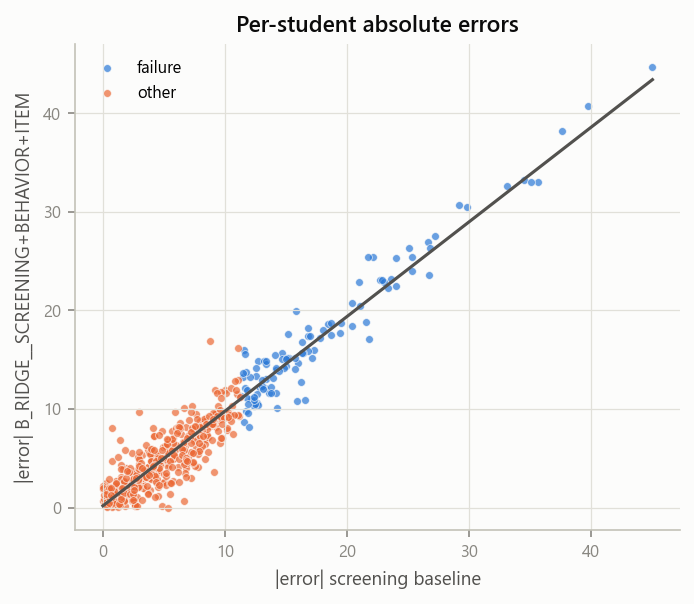

**failure_recovery**

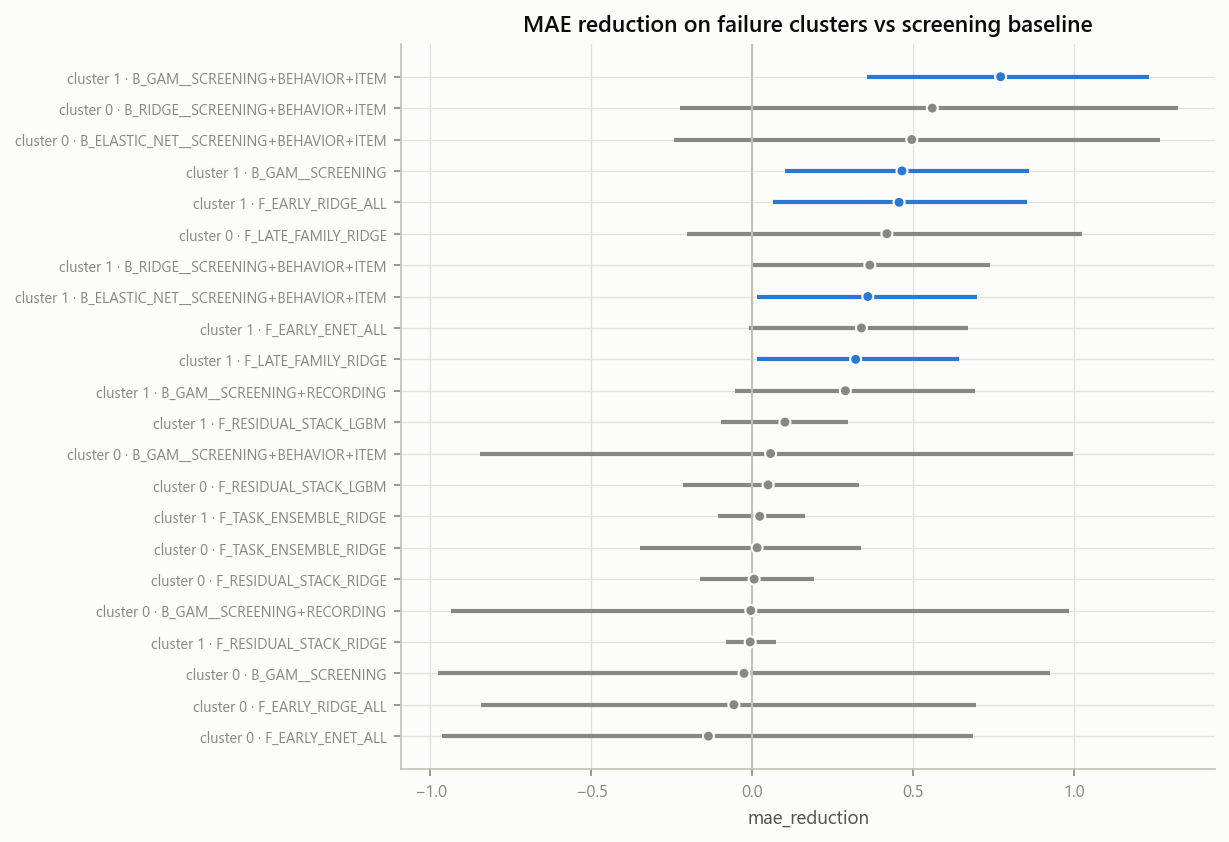

#### Tables (4 of 4)

**failure_recovery** — 22 rows × 9 cols · *key*

,failure_cluster,n,model,mae_baseline,mae_model,mae_reduction,ci_low,ci_high,recovers
0,0,28,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,16.72,16.23,0.4951,-0.244,1.265,False
1,0,28,B_GAM__SCREENING+BEHAVIOR+ITEM,16.72,16.66,0.0567,-0.8442,0.9966,False
2,0,28,B_GAM__SCREENING+RECORDING,16.72,16.73,-0.004694,-0.9361,0.9831,False
3,0,28,B_GAM__SCREENING,16.72,16.75,-0.0258,-0.9755,0.9241,False
4,0,28,B_RIDGE__SCREENING+BEHAVIOR+ITEM,16.72,16.16,0.5588,-0.2237,1.322,False
5,0,28,F_EARLY_ENET_ALL,16.72,16.86,-0.1363,-0.9648,0.6851,False
6,0,28,F_EARLY_RIDGE_ALL,16.72,16.78,-0.05737,-0.8416,0.6948,False
7,0,28,F_LATE_FAMILY_RIDGE,16.72,16.3,0.4179,-0.2025,1.024,False
8,0,28,F_RESIDUAL_STACK_LGBM,16.72,16.67,0.0489,-0.2158,0.3312,False
9,0,28,F_RESIDUAL_STACK_RIDGE,16.72,16.72,0.005697,-0.1635,0.1906,False


**failure_cluster_selection** — 6 rows × 2 cols · *key*

,k,silhouette
0,2,0.1423
1,3,0.05098
2,4,0.05931
3,5,0.04303
4,6,0.03706
5,7,0.03733


**failure_cluster_profiles** — 2 rows × 8 cols

,failure_cluster,n,frac_underpredicted,outcome_mean,top_features,instrument_mix,original_sample_rate_mix,school_id_mix
0,0,28,0.4643,97.14,MFCC__sentence_repetition__mfcc10_mean__mean=+...,"ktea3:64%, wj4:36%","16000:86%, 11025:14%","8:25%, 5:21%, 16:14%"
1,1,81,0.6173,106.8,MFCC__sentence_repetition__dmfcc5_std__mean=+0...,"ktea3:60%, wj4:40%","16000:74%, 11025:26%","5:23%, 16:14%, 4:11%"


**student_errors_and_failure_clusters** — 541 rows × 41 cols

,subject_id,y_true,pred__B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,pred__B_GAM__SCREENING+BEHAVIOR+ITEM,pred__B_GAM__SCREENING+RECORDING,pred__B_GAM__SCREENING,pred__B_RIDGE__SCREENING+BEHAVIOR+ITEM,pred__B_RIDGE__SCREENING+RECORDING,pred__F_EARLY_ENET_ALL,pred__F_EARLY_RIDGE_ALL,pred__F_LATE_FAMILY_RIDGE,pred__F_RESIDUAL_STACK_LGBM,pred__F_RESIDUAL_STACK_RIDGE,pred__F_TASK_ENSEMBLE_RIDGE,abserr__B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,resid__B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,abserr__B_GAM__SCREENING+BEHAVIOR+ITEM,resid__B_GAM__SCREENING+BEHAVIOR+ITEM,abserr__B_GAM__SCREENING+RECORDING,resid__B_GAM__SCREENING+RECORDING,abserr__B_GAM__SCREENING,resid__B_GAM__SCREENING,abserr__B_RIDGE__SCREENING+BEHAVIOR+ITEM,resid__B_RIDGE__SCREENING+BEHAVIOR+ITEM,abserr__B_RIDGE__SCREENING+RECORDING,resid__B_RIDGE__SCREENING+RECORDING,abserr__F_EARLY_ENET_ALL,resid__F_EARLY_ENET_ALL,abserr__F_EARLY_RIDGE_ALL,resid__F_EARLY_RIDGE_ALL,abserr__F_LATE_FAMILY_RIDGE,resid__F_LATE_FAMILY_RIDGE,abserr__F_RESIDUAL_STACK_LGBM,resid__F_RESIDUAL_STACK_LGBM,abserr__F_RESIDUAL_STACK_RIDGE,resid__F_RESIDUAL_STACK_RIDGE,abserr__F_TASK_ENSEMBLE_RIDGE,resid__F_TASK_ENSEMBLE_RIDGE,failure_cluster,direction,is_failure
0,002067c5badc,104,100.9,100.5,99.63,99.46,101,99.84,99.67,99.95,100.8,100.4,99.82,99.27,3.148,3.148,3.531,3.531,4.371,4.371,4.539,4.539,3.028,3.028,4.164,4.164,4.334,4.334,4.051,4.051,3.152,3.152,3.558,3.558,4.183,4.183,4.729,4.729,-1,underpredicted,False
1,01a87157fa7d,88,90.48,92.77,94.39,94.44,89.93,91.43,88.83,87.37,89.48,91.51,90.53,90.64,2.484,-2.484,4.77,-4.77,6.391,-6.391,6.445,-6.445,1.932,-1.932,3.426,-3.426,0.8297,-0.8297,0.6339,0.6339,1.476,-1.476,3.507,-3.507,2.528,-2.528,2.639,-2.639,-1,overpredicted,False
2,02c6ac193043,89,94.91,93.38,93.19,93.37,94.58,95.55,94.61,93.43,94.46,95.24,95.24,94.8,5.913,-5.913,4.376,-4.376,4.189,-4.189,4.37,-4.37,5.578,-5.578,6.553,-6.553,5.612,-5.612,4.433,-4.433,5.457,-5.457,6.236,-6.236,6.238,-6.238,5.795,-5.795,-1,overpredicted,False
3,035deb215200,90,101.3,101.5,101.1,102,101.5,101,101.7,101.7,102,102.5,101.1,101.4,11.29,-11.29,11.49,-11.49,11.11,-11.11,12,-12,11.47,-11.47,10.97,-10.97,11.65,-11.65,11.73,-11.73,11.99,-11.99,12.47,-12.47,11.11,-11.11,11.37,-11.37,-1,overpredicted,False
4,03cc329f669e,96,97.35,96.25,95.11,95.11,96.93,97.13,98.4,98.56,97.49,96.68,97.12,97.39,1.352,-1.352,0.2505,-0.2505,0.8892,0.8892,0.891,0.891,0.9326,-0.9326,1.126,-1.126,2.399,-2.399,2.556,-2.556,1.486,-1.486,0.6815,-0.6815,1.123,-1.123,1.392,-1.392,-1,overpredicted,False
5,04ab699a2376,91,98.5,98.41,97.06,96.94,98.54,98.17,99.19,99.14,98.67,98.32,98.15,98.34,7.502,-7.502,7.415,-7.415,6.065,-6.065,5.94,-5.94,7.542,-7.542,7.171,-7.171,8.188,-8.188,8.142,-8.142,7.67,-7.67,7.317,-7.317,7.146,-7.146,7.336,-7.336,-1,overpredicted,False
6,04b3a58822bd,102,99.57,98.56,100.2,101.4,99.69,100.3,98.69,99.16,100.3,99.61,100.3,99.59,2.426,2.426,3.445,3.445,1.792,1.792,0.5929,0.5929,2.311,2.311,1.69,1.69,3.305,3.305,2.836,2.836,1.681,1.681,2.394,2.394,1.684,1.684,2.408,2.408,-1,underpredicted,False
7,063dbecf207b,103,99.49,98.3,100.5,101.5,99.5,100.6,101.2,101.6,100.2,100.3,101.1,100.8,3.513,3.513,4.699,4.699,2.522,2.522,1.505,1.505,3.503,3.503,2.441,2.441,1.831,1.831,1.39,1.39,2.819,2.819,2.726,2.726,1.927,1.927,2.164,2.164,-1,underpredicted,False
8,06fb45baaa44,82,87.76,92.52,94.75,93.88,87.58,84.42,88.37,88.07,85.25,84.85,84.3,85.05,5.755,-5.755,10.52,-10.52,12.75,-12.75,11.88,-11.88,5.58,-5.58,2.424,-2.424,6.366,-6.366,6.066,-6.066,3.252,-3.252,2.852,-2.852,2.304,-2.304,3.048,-3.048,-1,overpredicted,False
9,070ce8f34efd,89,96.53,95.75,96,95.99,95.95,97.43,96.58,96.34,96.13,97.51,97.42,97.22,7.531,-7.531,6.747,-6.747,6.999,-6.999,6.986,-6.986,6.948,-6.948,8.426,-8.426,7.575,-7.575,7.337,-7.337,7.128,-7.128,8.509,-8.509,8.424,-8.424,8.218,-8.218,-1,overpredicted,False


In [21]:
stage('P12', key_tables=['failure_recovery', 'failure_cluster_selection'])

---
## P13 · Champion
Robust ranking across schemes, CV stacking, conformal coverage → `models/champion_spec.json`.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P05,cached,2026-11-20T14:17:35
3,P10,cached,2026-11-20T15:29:06
4,P13,cached,2026-11-20T15:32:17


### P13 · `completed` · 7.1s

,key,value
0,champion,B_RIDGE__SCREENING+RECORDING
1,cv_r2,0.1982
2,stacked,False
3,n_candidates,116


#### Figures (1)

**candidate_ranking**

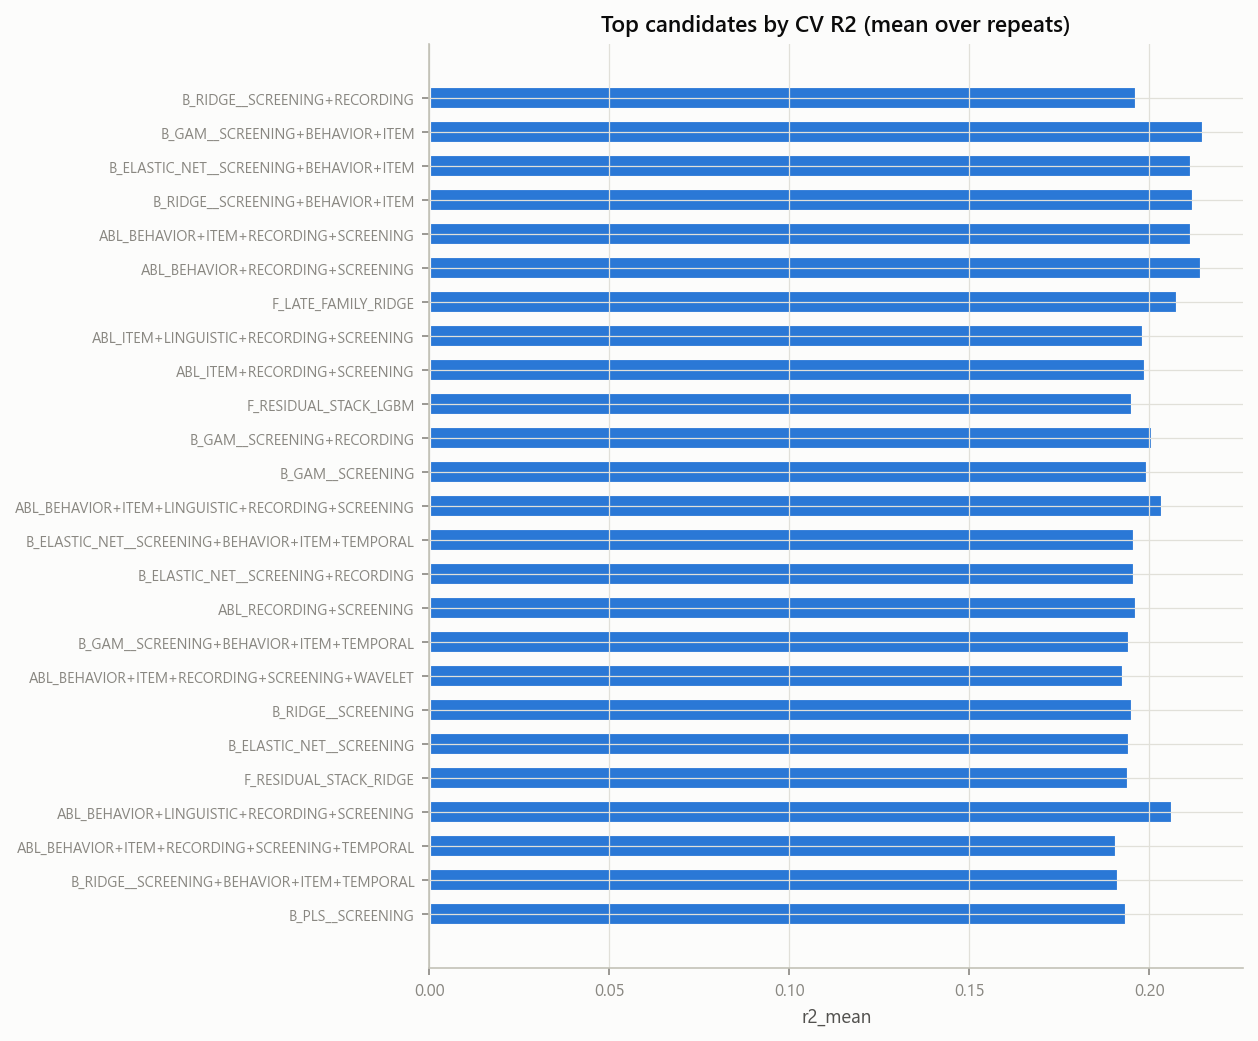

#### Tables (4 of 4)

**candidate_ranking** — 116 rows × 16 cols · *key*

,name,r2_mean,r2_sd,rmse_mean,mae_mean,r2_repeat_avg_pred,n_students,n_repeats,robust_score,delta_r2,delta_ci_low,delta_ci_high,delta_r2_repeat_mean,delta_r2_repeat_min,beats_baseline,deployable
0,B_RIDGE__SCREENING+RECORDING,0.1967,0.005896,9.972,7.392,0.1982,541,3,0.1908,0,NaN,NaN,NaN,NaN,True,True
1,B_GAM__SCREENING+BEHAVIOR+ITEM,0.2153,0.00212,9.856,7.299,0.2185,541,3,0.2131,0.02031,-0.009294,0.0493,0.01861,0.01453,False,True
2,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,0.2119,0.007338,9.877,7.3,0.2151,541,3,0.2045,0.01687,-0.006334,0.04015,0.01521,0.01317,False,True
3,B_RIDGE__SCREENING+BEHAVIOR+ITEM,0.2124,0.008279,9.874,7.277,0.2166,541,3,0.2041,0.01839,-0.005651,0.04172,0.01575,0.01261,False,True
4,ABL_BEHAVIOR+ITEM+RECORDING+SCREENING,0.212,0.00806,9.877,7.278,0.2162,541,3,0.2039,0.01795,-0.005575,0.0411,0.01531,0.01246,False,True
5,ABL_BEHAVIOR+RECORDING+SCREENING,0.2147,0.01325,9.859,7.266,0.2202,541,3,0.2014,0.02196,-0.001925,0.04628,0.018,0.007605,False,True
6,F_LATE_FAMILY_RIDGE,0.2078,0.01101,9.902,7.362,0.2135,541,3,0.1968,0.01531,-0.006456,0.0341,0.01116,0.004036,False,True
7,ABL_ITEM+LINGUISTIC+RECORDING+SCREENING,0.1984,0.002306,9.961,7.386,0.2018,541,3,0.1961,0.003547,-0.01747,0.02202,0.001792,-0.002365,False,True
8,ABL_ITEM+RECORDING+SCREENING,0.1989,0.002942,9.958,7.354,0.2014,541,3,0.196,0.00317,-0.01434,0.01894,0.002288,-0.0003935,False,True
9,F_RESIDUAL_STACK_LGBM,0.1954,0.001016,9.98,7.399,0.2008,541,3,0.1944,0.002594,-0.01054,0.01465,-0.001269,-0.006719,False,True


**champion_comparison** — 3 rows × 8 cols · *key*

,candidate,r2,r2_ci_low,r2_ci_high,rmse,mae,n,pearson
0,single:B_RIDGE__SCREENING+RECORDING,0.1982,0.1359,0.2459,9.962,7.382,541,0.4454
1,stack:nnls_cv,0.1952,0.13,0.2447,9.981,7.411,541,0.4419
2,baseline:B_RIDGE__SCREENING+RECORDING,0.1982,0.1359,0.2459,9.962,7.382,541,0.4454


**conformal_coverage** — 6 rows × 4 cols · *key*

,alpha,group,coverage,mean_width
0,0.1,all,0.902,31.21
1,0.1,ktea3,0.8925,31.22
2,0.1,wj4,0.9122,31.21
3,0.2,all,0.7948,22.64
4,0.2,ktea3,0.7599,22.65
5,0.2,wj4,0.8321,22.63


**stack_fold_weights** — 5 rows × 3 cols

,fold,intercept,B_RIDGE__SCREENING+RECORDING
0,0,-5.03,1.051
1,1,-0.8497,1.01
2,2,3.491,0.9648
3,3,-9.009,1.091
4,4,-2.923,1.03


**champion_spec.json**

{
  "name": "B_RIDGE__SCREENING+RECORDING",
  "members": [
    {
      "name": "B_RIDGE__SCREENING+RECORDING",
      "model": "RIDGE",
      "families": [
        "SCREENING",
        "RECORDING"
      ],
      "params": {},
      "selector_k": null
    }
  ],
  "weights": [
    1.0
  ],
  "intercept": 0.0,
  "audio_families": [
    "mel",
    "mfcc",
    "pitch",
    "quality",
    "spectral",
    "temporal",
    "wavelet"
  ],
  "cv_r2": 0.19823352138940697,
  "interval_q90": 15.722887824623056,
  "interval_q80": 11.329702957473385,
  "baseline": "B_RIDGE__SCREENING+RECORDING",
  "selection_rule": "robust score (mean - sd) among candidates whose delta-R2 CI > 0; stack only if > +0.005 R2"
}


In [22]:
stage('P13', key_tables=['candidate_ranking', 'champion_comparison', 'conformal_coverage'])

---
## P14 · Submission (off by default)
Independent re-load of the champion bundle and test inference. Set `RUN_SUBMISSION = True` in section 0 only after reviewing P13.

In [23]:
if RUN_SUBMISSION:
    sctx, spipe = setup("SUBMISSION", root=ROOT)
    display(spipe.run(["P14"]))
    _ctx, _pipe = ctx, pipe
    ctx, pipe = sctx, spipe
    show_results("P14", ["submission_meta"])
    ctx, pipe = _ctx, _pipe
else:
    print("P14 skipped (RUN_SUBMISSION = False)")

P14 skipped (RUN_SUBMISSION = False)


---
## P15 · Research report
Rebuilt last so it includes every stage above; rendered inline.

In [25]:
stage("P15", force=True)
rep = ROOT / "reports" / "WILDSPEECH_RESEARCH_REPORT.md"
if rep.exists():
    display(Markdown(rep.read_text(encoding="utf-8")))

15:41:01 | INFO    | === P15 report — scientific report


,stage,status,note
0,P15,completed,0.1s


### P15 · `completed` · 0.1s

,key,value
0,markdown,C:\Users\myben\Downloads\WildSpeech_P01\WildSp...
1,html,C:\Users\myben\Downloads\WildSpeech_P01\WildSp...


# WildSpeech — Literacy Signal Discovery Report

_Generated 2026-11-20 15:41 · profile FULL_

## Stage status

| stage | name | status | seconds | finished | note |
|---|---|---|---|---|---|
| P00 | infrastructure | completed | 24.05 | 2026-11-20T14:09:49 |  |
| P01 | tabular_eda | completed | 19.08 | 2026-11-20T14:10:08 |  |
| P02 | acoustic_eda | completed | 138.7 | 2026-11-20T14:12:27 |  |
| P03 | phonetic | disabled | 0 | 2026-11-20T14:20:57 | phonetic.enabled=false |
| P04 | embeddings | disabled | 0 | 2026-11-20T14:20:59 | embeddings.enabled=false |
| P05 | features | completed | 7.513 | 2026-11-20T14:17:35 |  |
| P06 | phenotypes | completed | 18.35 | 2026-11-20T14:19:09 |  |
| P07 | residual_discovery | completed | 71.3 | 2026-11-20T14:20:20 |  |
| P08 | robustness | completed | 3052 | 2026-11-20T15:12:24 |  |
| P09 | literacy_indices | completed | 11.4 | 2026-11-20T15:12:34 |  |
| P10 | model_benchmark | completed | 912.2 | 2026-11-20T15:29:06 |  |
| P11 | multimodal | completed | 271.8 | 2026-11-20T15:33:59 |  |
| P12 | failure_analysis | completed | 2.786 | 2026-11-20T15:32:10 |  |
| P13 | champion | completed | 7.143 | 2026-11-20T15:32:17 |  |
| P14 | submission | not run |  |  |  |
| P15 | report | running | 0 | 2026-11-20T15:41:01 |  |


**Hardware:** NVIDIA GeForce RTX 3070 Laptop GPU · torch 2.5.1+cu124 (CUDA 12.4) · RAM 16.5 GB · 16 logical CPUs


## Data integrity
| check | status | value | detail |
|---|---|---|---|
| train/test students disjoint | PASS | 0 | overlap count |
| unique train student ids | PASS | 0 | duplicates |
| unique test student ids | PASS | 0 | duplicates |
| every train student has a label | PASS | 0 | missing labels |
| labels only for train students | PASS | 0 | extra labels |
| target finite | PASS | 0 | non-finite |
| train clips map to known students | PASS | 0 | orphan subject ids |
| train students with >=1 clip | PASS | 0 | students without clips |
| train clip filenames unique | PASS | 0 | duplicates |
| train durations positive | PASS | 0 | non-positive |
| train item_score binary | PASS | [0.0, 1.0] | observed values |
| train clips present in TAR | PASS | 0 | metadata rows without audio |
| train TAR has no unlisted audio | PASS | 0 | audio without metadata |
| train TAR member paths safe | PASS | 0 | unsafe member names (ignored) |
| test clips map to known students | PASS | 0 | orphan subject ids |
| test students with >=1 clip | PASS | 0 | students without clips |
| test clip filenames unique | PASS | 0 | duplicates |
| test durations positive | PASS | 0 | non-positive |
| test item_score binary | PASS | [0.0, 1.0] | observed values |
| test clips present in TAR | PASS | 0 | metadata rows without audio |
| test TAR has no unlisted audio | PASS | 0 | audio without metadata |
| test TAR member paths safe | PASS | 0 | unsafe member names (ignored) |
| submission ids == test students | PASS | 0 | symmetric difference |
| school_id absent from test | PASS | nan | school_id is train-only: used for grouping/robustness, never as a feature |
| score_status absent from test | PASS | nan | behaviour features use item_score missingness instead (available in both splits) |
| blending_theta present in test | PASS | nan | screening score |
| deletion_theta present in test | PASS | nan | screening score |
| sentence_repetition_theta present in test | PASS | nan | screening score |


## Screening baselines (P01)
| name | r2_mean | r2_sd | rmse_mean | mae_mean |
|---|---|---|---|---|
| B00_MEAN | -0.0004624 | 0.0003371 | 11.13 | 8.211 |
| B01_RIDGE_SCREENING | 0.1954 | 0.006347 | 9.98 | 7.442 |
| B02_RIDGE_SCREENING_RECORDING | 0.1967 | 0.005896 | 9.972 | 7.392 |
| B03_RIDGE_SCR_BEH_ITEM | 0.212 | 0.00806 | 9.877 | 7.278 |
| B04_RIDGE_TABULAR_ALL | 0.2074 | 0.009603 | 9.905 | 7.306 |
| B05_LGBM_TABULAR_ALL | 0.1853 | 0.004482 | 10.04 | 7.467 |


## Screening scores vs outcome
| screening | scope | spearman | ci_low | ci_high | q |
|---|---|---|---|---|---|
| blending_theta | all | 0.4585 | 0.383 | 0.5262 | 1.081e-26 |
| blending_theta | instrument=ktea3 | 0.4114 | 0.301 | 0.5094 | 1.109e-11 |
| blending_theta | instrument=wj4 | 0.5231 | 0.4313 | 0.6052 | 1.964e-18 |
| deletion_theta | all | 0.3907 | 0.3002 | 0.478 | 3.513e-13 |
| deletion_theta | instrument=ktea3 | 0.489 | 0.2811 | 0.6593 | 9.847e-06 |
| deletion_theta | instrument=wj4 | 0.3532 | 0.2389 | 0.4624 | 8.268e-09 |
| sentence_repetition_theta | all | 0.2902 | 0.2113 | 0.3677 | 2.956e-11 |
| sentence_repetition_theta | instrument=ktea3 | 0.3096 | 0.1971 | 0.4242 | 5.457e-07 |
| sentence_repetition_theta | instrument=wj4 | 0.2854 | 0.1666 | 0.399 | 3.303e-06 |
| theta_mean | all | 0.4365 | 0.3652 | 0.4988 | 8.453e-26 |
| theta_mean | instrument=ktea3 | 0.447 | 0.3449 | 0.5474 | 1.239e-14 |
| theta_mean | instrument=wj4 | 0.4371 | 0.335 | 0.5342 | 2.874e-13 |


## Acoustic correctness contrasts (P02, item-centred)
| task | feature | cliffs_delta | std_diff | q |
|---|---|---|---|---|
| sentence_repetition | PITCH::voiced_ratio | 0.4812 | 0.8026 | 1.43e-213 |
| sentence_repetition | MEL::melband1_mean | 0.4746 | 0.7885 | 5.47e-208 |
| sentence_repetition | MEL::melband2_mean | 0.4623 | 0.7671 | 1.632e-197 |
| sentence_repetition | MEL::logmel_mean | 0.4481 | 0.7344 | 8.519e-186 |
| sentence_repetition | MFCC::mfcc0_mean | 0.4481 | 0.7344 | 8.519e-186 |
| sentence_repetition | SPECTRAL::slope_p50 | -0.4448 | -0.7535 | 3.309e-183 |
| sentence_repetition | MFCC::dmfcc4_std | 0.4441 | 0.7548 | 1.111e-182 |
| sentence_repetition | MFCC::dmfcc1_std | 0.437 | 0.7449 | 6.046e-177 |
| sentence_repetition | SPECTRAL::entropy_p50 | 0.435 | 0.7651 | 2.054e-175 |
| sentence_repetition | MFCC::dmfcc3_std | 0.4336 | 0.7379 | 2.756e-174 |
| sentence_repetition | SPECTRAL::rolloff_p50 | 0.4322 | 0.7224 | 3.172e-173 |
| sentence_repetition | MFCC::mfcc11_mean | -0.4307 | -0.73 | 4.257e-172 |
| sentence_repetition | MFCC::mfcc4_mean | -0.4288 | -0.7302 | 1.476e-170 |
| sentence_repetition | MEL::melband3_mean | 0.4271 | 0.7058 | 2.795e-169 |
| sentence_repetition | SPECTRAL::slope_mean | -0.4224 | -0.7151 | 1.213e-165 |


## Residual discovery (P07)
| feature | rho_resid | rho_ci_low | rho_ci_high | q_resid | replication_rate |
|---|---|---|---|---|---|
| BEHAVIOR__blending__max_difficulty_correct__value | 0.1642 | 0.07443 | 0.2522 | 0.5272 | 0.6667 |
| WAVELET__all__wl_rel_d5__std | 0.1292 | 0.04956 | 0.2156 | 0.9995 | 0 |
| SPECTRAL__blending__flatness_mean__median | 0.1293 | 0.0471 | 0.2141 | 0.9995 | 0.1111 |
| QUALITY__deletion__hf_ratio__slope | 0.1608 | 0.04896 | 0.2655 | 0.9995 | 0.5 |
| QUALITY__deletion__noise_floor_db__p90 | 0.1588 | 0.05263 | 0.26 | 0.9995 | 0.125 |
| QUALITY__all__noise_floor_db__mean | 0.1196 | 0.03454 | 0.2051 | 0.9995 | 0 |
| QUALITY__blending__snr_db__contrast | -0.1216 | -0.204 | -0.03641 | 0.9995 | 0 |
| SPECTRAL__blending__bandwidth_mean__median | 0.117 | 0.02577 | 0.1993 | 0.9995 | 0 |
| TEMPORAL__blending__trailing_silence_s__p90 | 0.117 | 0.03001 | 0.1986 | 0.9995 | 0 |
| TEMPORAL__blending__pause_ratio__slope | -0.1116 | -0.2003 | -0.03468 | 0.9995 | 0 |
| TEMPORAL__blending__nucleus_rate__p90 | 0.1102 | 0.02586 | 0.1935 | 0.9995 | 0 |
| PITCH__deletion__jitter_proxy__median | -0.1367 | -0.2466 | -0.03394 | 0.9995 | 0 |
| QUALITY__sentence_repetition__noise_floor_db__p10 | 0.1094 | 0.02385 | 0.1911 | 0.9995 | 0 |
| SPECTRAL__blending__centroid_std__median | 0.1059 | 0.02576 | 0.1889 | 0.9995 | 0 |
| SPECTRAL__blending__bandwidth_p90__mean | 0.1043 | 0.01357 | 0.1911 | 0.9995 | 0 |


### Matched over- vs under-achievers
| feature | n_pairs | mean_diff | cohens_d | q |
|---|---|---|---|---|
| TEMPORAL__blending__pause_ratio__slope | 54 | -0.1441 | -0.4338 | 0.4039 |
| TEMPORAL__deletion__long_pauses__std | 24 | -0.4921 | -0.6644 | 0.4039 |
| TEMPORAL__deletion__trailing_silence_s__median | 24 | 0.002653 | 0.01368 | 0.4039 |
| QUALITY__sentence_repetition__noise_floor_db__p10 | 53 | 0.1698 | 0.2617 | 0.4039 |
| MEL__all__melband7_mean__mean | 57 | 0.1457 | 0.3833 | 0.4039 |
| MEL__blending__melband7_mean__mean | 54 | 0.1655 | 0.3932 | 0.4039 |
| QUALITY__all__noise_floor_db__mean | 57 | 0.1007 | 0.2848 | 0.4039 |
| TEMPORAL__blending__mean_pause_s__slope | 54 | -0.1403 | -0.3382 | 0.47 |
| QUALITY__blending__snr_db__contrast | 53 | -0.1441 | -0.368 | 0.4706 |
| BEHAVIOR__blending__max_difficulty_correct__value | 51 | 0.1286 | 0.198 | 0.4938 |
| TEMPORAL__blending__trailing_silence_s__p90 | 54 | 0.09722 | 0.08686 | 0.4948 |
| WAVELET__blending__wl_rel_d1__mean | 54 | 0.0468 | 0.1706 | 0.4948 |
| WAVELET__all__wl_rel_d5__std | 57 | 0.0396 | 0.1476 | 0.4948 |
| SPECTRAL__blending__flatness_mean__median | 54 | 0.07412 | 0.2584 | 0.516 |
| BEHAVIOR__blending__mean_difficulty__value | 54 | 0.07331 | 0.1543 | 0.5393 |


## Phenotypes (P06)
| cluster | n | outcome_mean | outcome_ci_low | outcome_ci_high | instrument_top | original_sample_rate_top | school_id_top | outcome_eta2 | outcome_p |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 344 | 98.97 | 97.82 | 100.1 | ktea3 (55%) | 16000 (74%) | 5 (31%) | 0.01564 | 0.001147 |
| 1 | 197 | 96.08 | 94.62 | 97.59 | wj4 (54%) | 16000 (83%) | 5 (23%) | 0.01564 | 0.001147 |


## Robustness (P08)
### Domain generalisation
| name | scheme | r2_mean | r2_sd | n_students |
|---|---|---|---|---|
| DG_SCREENING | repeated_kfold | 0.1967 | 0.005896 | 541 |
| DG_SCREENING | loso | 0.1441 | 0.2943 | 541 |
| DG_SCREENING | instrument_transfer | 0.03281 | 0.07599 | 541 |
| DG_SCREENING | sample_rate_transfer | 0.08588 | 0.01632 | 541 |
| DG_SCREENING | school_kfold | 0.1236 | 0.2154 | 541 |
| DG_BEST | repeated_kfold | 0.182 | 0.002441 | 541 |
| DG_BEST | loso | 0.1461 | 0.2775 | 541 |
| DG_BEST | instrument_transfer | 0.05448 | 0.009169 | 541 |
| DG_BEST | sample_rate_transfer | -0.3786 | 0.3423 | 541 |
| DG_BEST | school_kfold | 0.1311 | 0.217 | 541 |


### Artifact-adjusted associations
| feature | partial_rho_adj | q_adj |
|---|---|---|
| QUALITY__all__clipping_ratio__std | 0.1768 | 0.06272 |
| TEMPORAL__blending__onset_latency_s__p10 | -0.1554 | 0.313 |
| WAVELET__all__wl_rel_d5__std | 0.133 | 0.8833 |
| QUALITY__deletion__noise_floor_db__p90 | 0.1684 | 0.8833 |
| PITCH__all__jitter_proxy__mean | -0.1151 | 0.9927 |
| WAVELET__all__wl_entropy__mean | -0.1147 | 0.9927 |
| PITCH__deletion__jitter_proxy__median | -0.1454 | 0.9927 |
| WAVELET__all__wl_rel_d1__std | 0.1116 | 0.9927 |
| PITCH__sentence_repetition__voicing_strength__std | -0.1123 | 0.9927 |
| TEMPORAL__blending__trailing_silence_s__p90 | 0.1112 | 0.9927 |
| QUALITY__sentence_repetition__dynamic_range_db__std | -0.1118 | 0.9927 |
| PITCH__sentence_repetition__jitter_proxy__median | -0.1111 | 0.9927 |
| WAVELET__sentence_repetition__wl_kurt_d1__std | -0.1105 | 0.9927 |
| SPECTRAL__deletion__flux_p90__std | 0.1354 | 0.9927 |
| TEMPORAL__deletion__trailing_silence_s__median | -0.1339 | 0.9927 |


## Experimental literacy indices (P09)
> Indices are experimental measurement constructs derived from anonymised assessment audio. They are not established educational or clinical diagnoses and must not be used to label students.

| index | delta_r2 | ci_low | ci_high | cronbach_alpha_mean | spearman_brown | sign_stability |
|---|---|---|---|---|---|---|
| PHONOLOGICAL_PRECISION | 0.004995 | -0.004488 | 0.01316 | -1.102 | 0.542 | 1 |
| FLUENCY | -0.002401 | -0.009391 | 0.00328 | 0.2727 | 0.3612 | 0.8889 |
| CONSISTENCY | -0.01554 | -0.02707 | -0.004459 | 0.1656 | 0.3587 | 0.6083 |
| COMPLEXITY_SENSITIVITY | -0.004201 | -0.0122 | 0.003362 | 0.3352 | 0.1669 | 0.6148 |


## Model benchmark (P10)
| name | r2_mean | r2_sd | delta_r2 | delta_ci_low | delta_ci_high |
|---|---|---|---|---|---|
| B_RIDGE__SCREENING | 0.1954 | 0.006347 | -0.001401 | -0.009201 | 0.005898 |
| B_RIDGE__SCREENING+RECORDING | 0.1967 | 0.005896 |  |  |  |
| B_RIDGE__SCREENING+BEHAVIOR+ITEM | 0.2124 | 0.008279 | 0.01839 | -0.005651 | 0.04172 |
| B_RIDGE__SCREENING+BEHAVIOR+ITEM+TEMPORAL | 0.1916 | 0.005801 | -0.000917 | -0.02781 | 0.02783 |
| B_RIDGE__ALL | 0.182 | 0.002441 | -0.009075 | -0.03853 | 0.01885 |
| B_ELASTIC_NET__SCREENING | 0.1946 | 0.005818 | -0.002022 | -0.009696 | 0.005153 |
| B_ELASTIC_NET__SCREENING+RECORDING | 0.1959 | 0.005017 | -0.0005995 | -0.002101 | 0.0008502 |
| B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM | 0.2119 | 0.007338 | 0.01687 | -0.006334 | 0.04015 |
| B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM+TEMPORAL | 0.1961 | 0.005163 | 0.004193 | -0.02142 | 0.03124 |
| B_ELASTIC_NET__ALL | 0.1859 | 0.004157 | -0.007229 | -0.03448 | 0.02106 |
| B_PLS__SCREENING | 0.1939 | 0.008592 | -0.002089 | -0.0136 | 0.007431 |
| B_PLS__SCREENING+RECORDING | 0.1936 | 0.008786 | -0.001528 | -0.009324 | 0.005186 |
| B_PLS__SCREENING+BEHAVIOR+ITEM | 0.1896 | 0.01075 | 0.003791 | -0.02616 | 0.0308 |
| B_PLS__SCREENING+BEHAVIOR+ITEM+TEMPORAL | 0.1752 | 0.0008281 | -0.01106 | -0.04588 | 0.02285 |
| B_PLS__ALL | 0.1802 | 0.005319 | -0.01072 | -0.04509 | 0.02009 |
| B_GAM__SCREENING | 0.1995 | 0.00746 | 0.004614 | -0.02081 | 0.02771 |
| B_GAM__SCREENING+RECORDING | 0.2009 | 0.006763 | 0.006286 | -0.01771 | 0.0282 |
| B_GAM__SCREENING+BEHAVIOR+ITEM | 0.2153 | 0.00212 | 0.02031 | -0.009294 | 0.0493 |
| B_GAM__SCREENING+BEHAVIOR+ITEM+TEMPORAL | 0.1945 | 0.003806 | 0.000728 | -0.03365 | 0.0357 |
| B_GAM__ALL | 0.1869 | 0.005928 | -0.004838 | -0.04105 | 0.03099 |
| B_CATBOOST__SCREENING |  |  |  |  |  |
| B_CATBOOST__SCREENING+RECORDING |  |  |  |  |  |
| B_CATBOOST__SCREENING+BEHAVIOR+ITEM |  |  |  |  |  |
| B_CATBOOST__SCREENING+BEHAVIOR+ITEM+TEMPORAL |  |  |  |  |  |
| B_CATBOOST__ALL |  |  |  |  |  |


### Family ablation
| families | kind | r2_mean | delta_r2 | delta_ci_low | delta_ci_high |
|---|---|---|---|---|---|
| BEHAVIOR+RECORDING+SCREENING | single_add | 0.2147 | 0.02196 | -0.006041 | 0.04517 |
| BEHAVIOR+ITEM+RECORDING+SCREENING | forward | 0.212 | 0.01795 | -0.008255 | 0.0407 |
| BEHAVIOR+LINGUISTIC+RECORDING+SCREENING | forward | 0.2066 | 0.01541 | -0.01512 | 0.04251 |
| BEHAVIOR+ITEM+LINGUISTIC+RECORDING+SCREENING | subset_3 | 0.2036 | 0.01138 | -0.01807 | 0.03791 |
| ITEM+RECORDING+SCREENING | single_add | 0.1989 | 0.00317 | -0.01532 | 0.01835 |
| ITEM+LINGUISTIC+RECORDING+SCREENING | subset_2 | 0.1984 | 0.003547 | -0.0179 | 0.02295 |
| RECORDING+SCREENING | base | 0.1967 | 0 |  |  |
| BEHAVIOR+ITEM+RECORDING+SCREENING+WAVELET | subset_3 | 0.1928 | 0.001001 | -0.02982 | 0.02689 |
| BEHAVIOR+ITEM+RECORDING+SCREENING+TEMPORAL | subset_3 | 0.191 | -0.0009786 | -0.02964 | 0.03007 |
| BEHAVIOR+RECORDING+SCREENING+WAVELET | forward | 0.1887 | -0.001781 | -0.03489 | 0.02739 |
| BEHAVIOR+RECORDING+SCREENING+TEMPORAL | forward | 0.1853 | -0.005113 | -0.0347 | 0.0278 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.1845 | -0.006518 | -0.03478 | 0.02177 |
| BEHAVIOR+ITEM+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.1843 | -0.006666 | -0.03659 | 0.02172 |
| LINGUISTIC+RECORDING+SCREENING | single_add | 0.1832 | -0.01168 | -0.02916 | 0.003747 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+PITCH+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.1825 | -0.009647 | -0.04011 | 0.01968 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.1824 | -0.008559 | -0.03975 | 0.02136 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+WAVELET | leave_one_out | 0.1823 | -0.009365 | -0.03638 | 0.01447 |
| BEHAVIOR+MEL+RECORDING+SCREENING | forward | 0.182 | -0.009275 | -0.04059 | 0.01803 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | all | 0.182 | -0.009075 | -0.03916 | 0.01791 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL | leave_one_out | 0.1815 | -0.009824 | -0.04049 | 0.0213 |
| BEHAVIOR+ITEM+LINGUISTIC+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.181 | -0.01001 | -0.04093 | 0.01902 |
| BEHAVIOR+ITEM+MEL+RECORDING+SCREENING | subset_3 | 0.1791 | -0.01332 | -0.04312 | 0.01239 |
| BEHAVIOR+LINGUISTIC+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+SPECTRAL+TEMPORAL+WAVELET | leave_one_out | 0.179 | -0.0105 | -0.0407 | 0.02018 |
| BEHAVIOR+ITEM+RECORDING+SCREENING+SPECTRAL | subset_3 | 0.1781 | -0.01393 | -0.04218 | 0.01214 |
| BEHAVIOR+ITEM+LINGUISTIC+MEL+MFCC+PITCH+QUALITY+RECORDING+SCREENING+TEMPORAL+WAVELET | leave_one_out | 0.178 | -0.01297 | -0.04244 | 0.01456 |


## Multimodal learning (P11)
| name | r2_mean | r2_sd | vs_best_p10_delta_r2 | vs_best_p10_delta_ci_low |
|---|---|---|---|---|
| F_EARLY_RIDGE_ALL | 0.182 | 0.002441 | -0.02939 | -0.06056 |
| F_EARLY_ENET_ALL | 0.1859 | 0.004157 | -0.02754 | -0.05 |
| F_LATE_FAMILY_RIDGE | 0.2078 | 0.01101 | -0.005002 | -0.02804 |
| F_TASK_ENSEMBLE_RIDGE | -1819 | 2572 | -606.6 | -2099 |
| F_RESIDUAL_STACK_RIDGE | 0.1945 | 0.006777 | -0.02133 | -0.05029 |
| F_RESIDUAL_STACK_LGBM | 0.1954 | 0.001016 | -0.01772 | -0.04544 |


## Failure analysis (P12)
| failure_cluster | n | frac_underpredicted | outcome_mean | top_features | instrument_mix | original_sample_rate_mix | school_id_mix |
|---|---|---|---|---|---|---|---|
| 0 | 28 | 0.4643 | 97.14 | MFCC__sentence_repetition__mfcc10_mean__mean=+1.28; SPECTRAL__sentence_repetition__entropy_p90__mean=-1.28; WAVELET__all__wl_log_energy__std=+1.28; MEL__all__melband1_mean__mean=-1.27; SPECTRAL__sentence_repetition__entropy_mean__p90=-1.26; MFCC__all__mfcc5_mean__mean=+1.26; MFCC__sentence_repetition__mfcc7_mean__mean=+1.25; SPECTRAL__sentence_repetition__entropy_mean__mean=-1.25 | ktea3:64%, wj4:36% | 16000:86%, 11025:14% | 8:25%, 5:21%, 16:14% |
| 1 | 81 | 0.6173 | 106.8 | MFCC__sentence_repetition__dmfcc5_std__mean=+0.44; ITEM__blending__irt_theta__value=+0.44; MFCC__sentence_repetition__dmfcc6_std__mean=+0.43; MFCC__sentence_repetition__dmfcc4_std__mean=+0.42; BEHAVIOR__blending__max_difficulty_correct__value=+0.42; MFCC__sentence_repetition__dmfcc7_std__mean=+0.41; MFCC__sentence_repetition__mfcc11_mean__mean=-0.41; SPECTRAL__sentence_repetition__entropy_mean__median=+0.40 | ktea3:60%, wj4:40% | 16000:74%, 11025:26% | 5:23%, 16:14%, 4:11% |


## Champion (P13)
| candidate | r2 | r2_ci_low | r2_ci_high | rmse | mae | n | pearson |
|---|---|---|---|---|---|---|---|
| single:B_RIDGE__SCREENING+RECORDING | 0.1982 | 0.1359 | 0.2459 | 9.962 | 7.382 | 541 | 0.4454 |
| stack:nnls_cv | 0.1952 | 0.13 | 0.2447 | 9.981 | 7.411 | 541 | 0.4419 |
| baseline:B_RIDGE__SCREENING+RECORDING | 0.1982 | 0.1359 | 0.2459 | 9.962 | 7.382 | 541 | 0.4454 |


| alpha | group | coverage | mean_width |
|---|---|---|---|
| 0.1 | all | 0.902 | 31.21 |
| 0.1 | ktea3 | 0.8925 | 31.22 |
| 0.1 | wj4 | 0.9122 | 31.21 |
| 0.2 | all | 0.7948 | 22.64 |
| 0.2 | ktea3 | 0.7599 | 22.65 |
| 0.2 | wj4 | 0.8321 | 22.63 |


## Submission (P14)
_not generated_


## Hypothesis registry
| hypothesis_id | statement | status | evidence | effect | q_value |
|---|---|---|---|---|---|
| H01 | Fold-fitted IRT/difficulty-adjusted accuracy adds predictive value beyond the provided task thetas. | not_supported | base+ITEM delta R2=0.0032 | 0.00317 |  |
| H02 | Response timing (onset latency, pauses, speech rate) predicts outcome beyond screening scores. | proposed | None |  |  |
| H03 | Spectral/MFCC characteristics carry residual signal after controlling for recording quality. | not_supported | 0 SPECTRAL/MFCC/MEL features with artifact-adjusted q<0.05 | 0.1354 | 0.9927 |
| H04 | Acoustic features differ between correct and incorrect responses to the same item. | supported | 303 item-centred contrasts with q<0.05; strongest sentence_repetition:PITCH::voiced_ratio | 0.4812 | 1.43e-213 |
| H05 | Students cluster into reproducible speech/literacy phenotypes. | supported | best k=2, bootstrap ARI=0.84, outcome eta2=0.016 | 0.8371 |  |
| H06 | Acoustic signals in screening-residuals survive school adjustment. | not_supported | 0 acoustic features keep sign and q<0.05 after school demeaning |  |  |
| H07 | Original recording sample rate (11025 vs 16000) acts as a confound of acoustic features. | not_supported | 1.0% of acoustic features /rho/ with low original sample rate > flag | 0.01035 |  |
| H08 | Composite literacy indices provide incremental predictive value over screening. | proposed | None |  |  |
| H09 | Multimodal fusion improves R2 over the best single-family model. | not_supported | best fusion F_LATE_FAMILY_RIDGE vs best P10 B_GAM__SCREENING+BEHAVIOR+ITEM: delta R2=-0.0050 | -0.005002 |  |
| H10 | Pronunciation confidence (CTC GOP) predicts outcome beyond accuracy. | proposed | None |  |  |
| H11 | Large baseline failures form identifiable clusters that some modality recovers. | proposed | None |  |  |
| H12 | Signal generalises across schools (LOSO R2 within 0.05 of repeated K-fold). | supported | LOSO R2=0.146 vs repeated K-fold R2=0.182 | -0.03583 |  |


## Recommendations
- No single feature family produced a delta-R2 CI above 0; prioritise screening + item-level features.
- 453 acoustic student features correlate with recording-quality covariates above the flag; use artifact-adjusted estimates when interpreting them.
- 115 clip features are unstable under at least one perturbation (pitch shift / noise / low-pass); treat them as anonymisation-sensitive.
- 1 baseline failure clusters are recovered by at least one model.


## Safeguards
- All audio processed locally; no external APIs; models loaded with local_files_only.
- Student-disjoint folds; item statistics, IRT, PCA, selection, stacking fitted inside training folds.
- No test labels, test-fitted normalisation or pseudo-labelling; school_id/score_status never used as features.
- Indices are experimental measurements, not diagnoses.


---
## Experiment summary

In [26]:
display(Markdown("**Stage status**"))
display(pipe.status_table())
if RUN_LOG:
    display(Markdown("**This session's runs**"))
    display(pd.concat(RUN_LOG, ignore_index=True))

**Stage status**

,stage,name,status,up_to_date,seconds,finished,note,enabled,expensive
0,P00,infrastructure,completed,True,24.05,2026-11-20T14:09:49,,True,False
1,P01,tabular_eda,completed,True,19.08,2026-11-20T14:10:08,,True,False
2,P02,acoustic_eda,completed,True,138.7,2026-11-20T14:12:27,,True,True
3,P03,phonetic,disabled,None,0,2026-11-20T14:20:57,phonetic.enabled=false,False,True
4,P04,embeddings,disabled,None,0,2026-11-20T14:20:59,embeddings.enabled=false,False,True
5,P05,features,completed,True,7.513,2026-11-20T14:17:35,,True,False
6,P06,phenotypes,completed,True,18.35,2026-11-20T14:19:09,,True,False
7,P07,residual_discovery,completed,True,71.3,2026-11-20T14:20:20,,True,False
8,P08,robustness,completed,False,3052,2026-11-20T15:12:24,,True,False
9,P09,literacy_indices,completed,True,11.4,2026-11-20T15:12:34,,True,False


**This session's runs**

,stage,status,note,wall_s
0,P00,cached,2026-11-20T14:09:49,0
1,P00,cached,2026-11-20T14:09:49,0
2,P00,cached,2026-11-20T14:09:49,0
3,P00,cached,2026-11-20T14:09:49,0
4,P00,cached,2026-11-20T14:09:49,0
5,P00,cached,2026-11-20T14:09:49,0
6,P01,cached,2026-11-20T14:10:08,0
7,P00,cached,2026-11-20T14:09:49,0
8,P02,cached,2026-11-20T14:12:27,0
9,P00,cached,2026-11-20T14:09:49,0


In [27]:
exp = ctx.registries.experiments.frame()
if exp.empty or "r2_mean" not in exp:
    print("no experiments registered yet")
else:
    exp = exp.dropna(subset=["r2_mean"]).copy()
    display(Markdown(f"**Experiment registry** — {len(exp)} experiments, top 25 by mean R²"))
    display(exp.sort_values("r2_mean", ascending=False).head(25))

    # best R² per scheme, top 20 configurations
    top = (exp.sort_values("r2_mean", ascending=False).drop_duplicates(["name", "scheme"])
              .groupby("scheme", group_keys=False).head(20))
    for scheme, g in top.groupby("scheme"):
        g = g.sort_values("r2_mean")
        fig, ax = plt.subplots(figsize=(9, 0.32 * len(g) + 1.2))
        ax.barh(g["name"].astype(str), g["r2_mean"], xerr=g.get("r2_sd"), color="#4C72B0", alpha=.85,
                error_kw={"elinewidth": .8, "ecolor": "#555"})
        base = exp[(exp["scheme"] == scheme) & exp["name"].astype(str).str.startswith("B01")]["r2_mean"]
        if len(base):
            ax.axvline(base.max(), color="#C44E52", ls="--", lw=1, label="screening-only ridge (B01)")
            ax.legend(loc="lower right", frameon=False)
        ax.set_xlabel("mean out-of-fold R²")
        ax.set_title(f"Top configurations — {scheme}")
        ax.spines[["top", "right"]].set_visible(False)
        plt.tight_layout()
        plt.show()

**Experiment registry** — 133 experiments, top 25 by mean R²

,experiment_id,stage,model,name,families,scheme,r2_mean,r2_sd,rmse,mae,n_features,config_hash,updated_at
34,P10:B_GAM__SCREENING+BEHAVIOR+ITEM:repeated_kf...,P10,GAM,B_GAM__SCREENING+BEHAVIOR+ITEM,SCREENING+BEHAVIOR+ITEM,repeated_kfold,0.2153,0.00212,9.856,7.299,108,c4ed03cd7313cee2,2026-11-20T15:17:48
48,P10:ABL_RIDGE_BEHAVIOR+RECORDING+SCREENING:rep...,P10,RIDGE,ABL_RIDGE_BEHAVIOR+RECORDING+SCREENING,BEHAVIOR+RECORDING+SCREENING,repeated_kfold,0.2147,0.01325,9.859,7.266,85,c4ed03cd7313cee2,2026-11-20T15:20:15
19,P10:B_RIDGE__SCREENING+BEHAVIOR+ITEM:repeated_...,P10,RIDGE,B_RIDGE__SCREENING+BEHAVIOR+ITEM,SCREENING+BEHAVIOR+ITEM,repeated_kfold,0.2124,0.008279,9.874,7.277,108,c4ed03cd7313cee2,2026-11-20T15:13:55
69,P10:ABL_RIDGE_BEHAVIOR+ITEM+RECORDING+SCREENIN...,P10,RIDGE,ABL_RIDGE_BEHAVIOR+ITEM+RECORDING+SCREENING,BEHAVIOR+ITEM+RECORDING+SCREENING,repeated_kfold,0.212,0.00806,9.877,7.278,110,c4ed03cd7313cee2,2026-11-20T15:24:27
3,P01:B03_RIDGE_SCR_BEH_ITEM:repeated_kfold:6bf9...,P01,RIDGE,B03_RIDGE_SCR_BEH_ITEM,SCREENING+RECORDING+BEHAVIOR+ITEM,repeated_kfold,0.212,0.00806,9.877,7.278,110,c4ed03cd7313cee2,2026-11-20T14:10:03
24,P10:B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM:rep...,P10,ELASTIC_NET,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,SCREENING+BEHAVIOR+ITEM,repeated_kfold,0.2119,0.007338,9.877,7.3,108,c4ed03cd7313cee2,2026-11-20T15:14:31
129,P11:F_LATE_FAMILY_RIDGE:repeated_kfold:ece020b...,P11,LATE_FUSION,F_LATE_FAMILY_RIDGE,ALL,repeated_kfold,0.2078,0.01101,9.902,7.362,1582,c4ed03cd7313cee2,2026-11-20T15:32:35
4,P01:B04_RIDGE_TABULAR_ALL:repeated_kfold:099ba...,P01,RIDGE,B04_RIDGE_TABULAR_ALL,SCREENING+RECORDING+BEHAVIOR+ITEM+LINGUISTIC,repeated_kfold,0.2074,0.009603,9.905,7.306,124.8,c4ed03cd7313cee2,2026-11-20T14:10:05
70,P10:ABL_RIDGE_BEHAVIOR+LINGUISTIC+RECORDING+SC...,P10,RIDGE,ABL_RIDGE_BEHAVIOR+LINGUISTIC+RECORDING+SCREENING,BEHAVIOR+LINGUISTIC+RECORDING+SCREENING,repeated_kfold,0.2066,0.01946,9.91,7.324,117.8,c4ed03cd7313cee2,2026-11-20T15:24:28
114,P10:ABL_RIDGE_BEHAVIOR+ITEM+LINGUISTIC+RECORDI...,P10,RIDGE,ABL_RIDGE_BEHAVIOR+ITEM+LINGUISTIC+RECORDING+S...,BEHAVIOR+ITEM+LINGUISTIC+RECORDING+SCREENING,repeated_kfold,0.2036,0.01202,9.928,7.336,130.8,c4ed03cd7313cee2,2026-11-20T15:28:11


C:\Users\myben\AppData\Local\Temp\ipykernel_29236\2699618077.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\myben\AppData\Local\Temp\ipykernel_29236\2699618077.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\myben\AppData\Local\Temp\ipykernel_29236\2699618077.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\myben\AppData\Local\Temp\ipykernel_29236\2699618077.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\myben\AppData\Local\Temp\ipykernel_29236\2699618077.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [28]:
hyp = ctx.registries.hypotheses.frame()
display(Markdown(f"**Hypothesis registry** — {len(hyp)} hypotheses"))
display(hyp)
spec = ROOT / "models" / "champion_spec.json"
if spec.exists():
    display(Markdown("**Champion spec**"))
    print(spec.read_text(encoding="utf-8")[:3000])

**Hypothesis registry** — 12 hypotheses

,hypothesis_id,statement,family,tested_in,rule,status,updated_at,evidence_stage,evidence,effect,ci_low,ci_high,q_value
0,H01,Fold-fitted IRT/difficulty-adjusted accuracy a...,ITEM,P10,ablation delta R2 of ITEM over the base has bo...,not_supported,2026-11-20T15:29:05,P10,base+ITEM delta R2=0.0032,0.00317,-0.01532,0.01835,NaN
1,H02,"Response timing (onset latency, pauses, speech...",TEMPORAL,P07,>= 1 TEMPORAL feature with FDR q < alpha for a...,proposed,2026-11-20T14:09:21,None,None,NaN,NaN,NaN,NaN
2,H03,Spectral/MFCC characteristics carry residual s...,SPECTRAL,P08,artifact-adjusted partial correlation keeps FD...,not_supported,2026-11-20T14:22:38,P08,0 SPECTRAL/MFCC/MEL features with artifact-adj...,0.1354,NaN,NaN,0.9927
3,H04,Acoustic features differ between correct and i...,ACOUSTIC,P02,>= 1 feature with item-centred correct-vs-inco...,supported,2026-11-20T14:12:25,P02,303 item-centred contrasts with q<0.05; strong...,0.4812,NaN,NaN,1.43e-213
4,H05,Students cluster into reproducible speech/lite...,PHENOTYPE,P06,best k has bootstrap mean ARI >= 0.6,supported,2026-11-20T14:19:09,P06,"best k=2, bootstrap ARI=0.84, outcome eta2=0.016",0.8371,NaN,NaN,NaN
5,H06,Acoustic signals in screening-residuals surviv...,ACOUSTIC,P08,school-demeaned association keeps sign and FDR...,not_supported,2026-11-20T14:22:17,P08,0 acoustic features keep sign and q<0.05 after...,NaN,NaN,NaN,NaN
6,H07,Original recording sample rate (11025 vs 16000...,RECORDING,P08,"|corr(feature, sr_11025)| > artifact flag for ...",not_supported,2026-11-20T14:22:29,P08,1.0% of acoustic features |rho| with low origi...,0.01035,NaN,NaN,NaN
7,H08,Composite literacy indices provide incremental...,INDEX,P09,>= 1 index with CV delta R2 bootstrap 95% CI > 0,proposed,2026-11-20T14:09:21,None,None,NaN,NaN,NaN,NaN
8,H09,Multimodal fusion improves R2 over the best si...,FUSION,P11,best fusion model delta R2 vs best P10 model C...,not_supported,2026-11-20T15:33:59,P11,best fusion F_LATE_FAMILY_RIDGE vs best P10 B_...,-0.005002,-0.02804,0.01827,NaN
9,H10,Pronunciation confidence (CTC GOP) predicts ou...,ALIGN,P07,>= 1 ALIGN feature FDR q < alpha against scree...,proposed,2026-11-20T14:09:21,None,None,NaN,NaN,NaN,NaN


**Champion spec**

{
  "name": "B_RIDGE__SCREENING+RECORDING",
  "members": [
    {
      "name": "B_RIDGE__SCREENING+RECORDING",
      "model": "RIDGE",
      "families": [
        "SCREENING",
        "RECORDING"
      ],
      "params": {},
      "selector_k": null
    }
  ],
  "weights": [
    1.0
  ],
  "intercept": 0.0,
  "audio_families": [
    "mel",
    "mfcc",
    "pitch",
    "quality",
    "spectral",
    "temporal",
    "wavelet"
  ],
  "cv_r2": 0.19823352138940697,
  "interval_q90": 15.722887824623056,
  "interval_q80": 11.329702957473385,
  "baseline": "B_RIDGE__SCREENING+RECORDING",
  "selection_rule": "robust score (mean - sd) among candidates whose delta-R2 CI > 0; stack only if > +0.005 R2"
}
